# Data Understanding

In [1]:
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titleweight"] = "bold"

# Folder output di direktori notebook saat ini
Path("figures").mkdir(exist_ok=True)
Path("artifacts").mkdir(exist_ok=True)

# === PATH DATASET ===
DATA_DIR = Path(r"C:\Users\vicen\Downloads\Data Scraping Opini Publik.csv")
FILE_PATH = DATA_DIR 

# Validasi keberadaan file sebelum load
if not FILE_PATH.exists():
    available_files = [f.name for f in DATA_DIR.glob("*") if f.suffix.lower() in [".csv", ".xlsx", ".xls"]]
    raise FileNotFoundError(
        f"File tidak ditemukan di: {FILE_PATH}\n"
        f"File tersedia di folder tersebut: {available_files}"
    )

if FILE_PATH.suffix.lower() == ".csv":
    df_raw = pd.read_csv(FILE_PATH)
elif FILE_PATH.suffix.lower() in [".xlsx", ".xls"]:
    df_raw = pd.read_excel(FILE_PATH)

print(f"Berhasil memuat : {FILE_PATH.name}")
print(f"Dimensi Dataset : {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")
display(df_raw.head(5))

Berhasil memuat : Data Scraping Opini Publik.csv
Dimensi Dataset : 52,372 baris x 7 kolom


,Platform,Source_ID,Tanggal,Username,Komentar,Jumlah_Like,Tipe_Konten
0,YouTube,FIogaI0vRFA,2026-11-19 15:52:50,@FpriPlayer,waktu pilpres saya memilih paslon ini karena ada gibran di sana,0,YouTube Reguler
1,YouTube,FIogaI0vRFA,2026-11-19 13:52:50,@Khabdullah-o3c,maju terus mas gibran,0,YouTube Reguler
2,YouTube,FIogaI0vRFA,2026-11-19 11:52:50,@NanaAurie,Mundur tanpa pengadilan ijasah wow,0,YouTube Reguler
3,YouTube,FIogaI0vRFA,2026-11-19 11:52:50,@riztasunny269,Mas Gibran capek karna GK sejalan dengan persiden,0,YouTube Reguler
4,YouTube,FIogaI0vRFA,2026-11-19 10:52:50,@EdiPondok-k2q,Y ...semoga aj...alam di Nusantara in punya pengertian .Ats. ...ke beranian jga kehendak BPK Gibran yg iklas jga...,0,YouTube Reguler


In [2]:
tanggal_dt = pd.to_datetime(df_raw["Tanggal"], errors="coerce")

print("=== RINGKASAN SUMBER DATA ===")
print(f"Nama File           : {FILE_PATH.name}")
print(f"Periode Data        : {tanggal_dt.min()} s.d. {tanggal_dt.max()}")
print(f"Tanggal Gagal Parse : {tanggal_dt.isna().sum()} baris")
print(f"Jumlah Baris        : {len(df_raw):,}")
print(f"Jumlah Kolom        : {df_raw.shape[1]}")
print("Kolom Target        : Belum tersedia (Sentimen akan dianotasi manual; Jalur A unsupervised)\n")

deskripsi_kolom = {
    "Platform": "Nama platform media sosial sumber komentar (YouTube, Reddit, Kaskus)",
    "Source_ID": "ID unik video/thread/postingan tempat komentar diambil",
    "Tanggal": "Waktu publikasi komentar (format YYYY-MM-DD HH:MM:SS)",
    "Username": "Nama akun/penulis komentar pada masing-masing platform",
    "Komentar": "Teks isi komentar opini publik",
    "Jumlah_Like": "Jumlah suka/skor engagement komentar (tersimpan sebagai object)",
    "Tipe_Konten": "Sub-kategori konten sumber (YouTube Shorts, YouTube Reguler, Reddit, Kaskus)"
}

kamus_data = pd.DataFrame({
    "Kolom": df_raw.columns,
    "Tipe_Data_Mentah": df_raw.dtypes.astype(str).values,
    "Jumlah_Unik": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],
    "Missing_Count": df_raw.isna().sum().values,
    "Keterangan": [deskripsi_kolom.get(c, "-") for c in df_raw.columns],
    "Contoh_Nilai": [df_raw[c].dropna().iloc[0] if not df_raw[c].dropna().empty else None for c in df_raw.columns]
})

print("=== KAMUS DATA ===")
display(kamus_data)

=== RINGKASAN SUMBER DATA ===
Nama File           : Data Scraping Opini Publik.csv
Periode Data        : 2025-02-06 13:57:00 s.d. 2026-11-20 00:04:47
Tanggal Gagal Parse : 0 baris
Jumlah Baris        : 52,372
Jumlah Kolom        : 7
Kolom Target        : Belum tersedia (Sentimen akan dianotasi manual; Jalur A unsupervised)

=== KAMUS DATA ===


,Kolom,Tipe_Data_Mentah,Jumlah_Unik,Missing_Count,Keterangan,Contoh_Nilai
0,Platform,str,3,0,"Nama platform media sosial sumber komentar (YouTube, Reddit, Kaskus)",YouTube
1,Source_ID,str,84,0,ID unik video/thread/postingan tempat komentar diambil,FIogaI0vRFA
2,Tanggal,str,2053,0,Waktu publikasi komentar (format YYYY-MM-DD HH:MM:SS),2026-11-19 15:52:50
3,Username,str,41298,0,Nama akun/penulis komentar pada masing-masing platform,@FpriPlayer
4,Komentar,str,50523,24,Teks isi komentar opini publik,waktu pilpres saya memilih paslon ini karena ada gibran di sana
5,Jumlah_Like,str,267,0,Jumlah suka/skor engagement komentar (tersimpan sebagai object),0
6,Tipe_Konten,str,4,0,"Sub-kategori konten sumber (YouTube Shorts, YouTube Reguler, Reddit, Kaskus)",YouTube Reguler


In [3]:
print("=== AUDIT KONDISI & KUALITAS DATA ===\n")

# 1. Missing Values & Duplikat
missing_summary = df_raw.isna().sum()
exact_dup = df_raw.duplicated().sum()
comment_dup_incl_na = df_raw["Komentar"].duplicated().sum()
comment_dup_non_na = df_raw["Komentar"].dropna().duplicated().sum()

print(f"1. Komentar Kosong (NaN)              : {missing_summary['Komentar']:,} baris")
print(f"2. Baris Duplikat Identik (7 kolom)   : {exact_dup:,} baris")
print(f"3. Teks Komentar Berulang (incl. NaN) : {comment_dup_incl_na:,} baris "
      f"({comment_dup_non_na:,} baris non-NaN)")

# 2. Audit Kolom Jumlah_Like
likes_numeric_naive = pd.to_numeric(df_raw["Jumlah_Like"], errors="coerce")
non_numeric_likes = df_raw[likes_numeric_naive.isna()]
neg_likes = df_raw[likes_numeric_naive < 0]

print(f"\n4. Audit Kolom Jumlah_Like:")
print(f"   - Nilai non-numerik (format 'rb')  : {len(non_numeric_likes):,} baris")
print(f"     Contoh nilai non-numerik         : {non_numeric_likes['Jumlah_Like'].unique()[:8].tolist()}")
print(f"   - Nilai negatif (< 0)              : {len(neg_likes):,} baris")
print("   - Sebaran nilai negatif per Platform:")
display(neg_likes["Platform"].value_counts().to_frame("Jumlah_Baris_Negatif"))

# 3. Audit Placeholder & Noise Spesifik Kaskus
kaskus_df = df_raw[df_raw["Platform"] == "Kaskus"]
kaskus_placeholder = kaskus_df[
    (kaskus_df["Username"] == "Username") | (kaskus_df["Komentar"] == "Isi Post")
]
kaskus_ui_noise = kaskus_df[
    kaskus_df["Komentar"].astype(str).str.contains(r"Bagikan$", regex=True, na=False)
]

print(f"\n5. Audit Noise Platform Kaskus:")
print(f"   - Placeholder ('Username'/'Isi Post') : {len(kaskus_placeholder):,} baris")
print(f"   - Noise UI/Sidebar (akhiran 'Bagikan'): {len(kaskus_ui_noise):,} baris")

kaskus_user_raw = kaskus_df["Username"].dropna().astype(str)
kaskus_user_norm = kaskus_user_raw.str.lstrip("@")
print(f"   - Username unik Kaskus (mentah)       : {kaskus_user_raw.nunique():,}")
print(f"   - Username unik Kaskus (tanpa '@')    : {kaskus_user_norm.nunique():,} "
      f"(duplikasi identitas akibat prefix '@')")

# 4. Komposisi Platform & Tipe Konten
print("\n6. Komposisi Platform & Tipe Konten:")
platform_summary = pd.DataFrame({
    "Jumlah_Baris": df_raw["Platform"].value_counts(),
    "Persentase (%)": (df_raw["Platform"].value_counts(normalize=True) * 100).round(2)
})
display(platform_summary)

tipe_summary = pd.DataFrame({
    "Jumlah_Baris": df_raw["Tipe_Konten"].value_counts(),
    "Persentase (%)": (df_raw["Tipe_Konten"].value_counts(normalize=True) * 100).round(2)
})
display(tipe_summary)

=== AUDIT KONDISI & KUALITAS DATA ===

1. Komentar Kosong (NaN)              : 24 baris
2. Baris Duplikat Identik (7 kolom)   : 345 baris
3. Teks Komentar Berulang (incl. NaN) : 1,848 baris (1,825 baris non-NaN)

4. Audit Kolom Jumlah_Like:
   - Nilai non-numerik (format 'rb')  : 19 baris
     Contoh nilai non-numerik         : ['1,3\xa0rb', '1,9\xa0rb', '3,3\xa0rb', '1,6\xa0rb', '5,6\xa0rb', '1,7\xa0rb', '1,5\xa0rb', '1\xa0rb']
   - Nilai negatif (< 0)              : 27 baris
   - Sebaran nilai negatif per Platform:


,Jumlah_Baris_Negatif
Platform,
Reddit,27



5. Audit Noise Platform Kaskus:
   - Placeholder ('Username'/'Isi Post') : 58 baris
   - Noise UI/Sidebar (akhiran 'Bagikan'): 41 baris
   - Username unik Kaskus (mentah)       : 332
   - Username unik Kaskus (tanpa '@')    : 325 (duplikasi identitas akibat prefix '@')

6. Komposisi Platform & Tipe Konten:


,Jumlah_Baris,Persentase (%)
Platform,,
YouTube,50140,95.74
Reddit,1156,2.21
Kaskus,1076,2.05


,Jumlah_Baris,Persentase (%)
Tipe_Konten,,
YouTube Shorts,26733,51.04
YouTube Reguler,23407,44.69
Reddit,1156,2.21
Kaskus,1076,2.05


In [4]:
df_eda = df_raw.copy()
df_eda["Tanggal_dt"] = pd.to_datetime(df_eda["Tanggal"], errors="coerce")

def parse_likes_eda(val):
    s = str(val).strip().lower().replace("\xa0", " ")
    if "rb" in s:
        return float(s.replace("rb", "").strip().replace(",", ".")) * 1000
    if "jt" in s:
        return float(s.replace("jt", "").strip().replace(",", ".")) * 1_000_000
    return pd.to_numeric(s, errors="coerce")

df_eda["Likes_Num"] = df_eda["Jumlah_Like"].apply(parse_likes_eda)
df_eda["Panjang_Karakter"] = df_eda["Komentar"].dropna().astype(str).str.len()
df_eda["Jumlah_Kata"] = df_eda["Komentar"].dropna().astype(str).str.split().str.len()

print("=== STATISTIK DESKRIPTIF ENGAGEMENT & PANJANG KOMENTAR ===")
display(
    df_eda[["Likes_Num", "Panjang_Karakter", "Jumlah_Kata"]]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    .round(2)
)

acc_counts = df_eda.groupby(["Platform", "Username"]).size()
print("\n=== ANALISIS ENTITAS & KECUKUPAN DATA AKUN (JALUR A) ===")
print(f"Total Source_ID Unik             : {df_eda['Source_ID'].nunique():,}")
print(f"Total Akun Unik (Platform+User)  : {len(acc_counts):,}")
print(f"Akun 1 Komentar (Tidak Cukup)    : {(acc_counts == 1).sum():,} ({(acc_counts == 1).mean()*100:.2f}%)")
print(f"Akun > 1 Komentar (Kandidat)     : {(acc_counts > 1).sum():,} ({(acc_counts > 1).mean()*100:.2f}%)")
print(f"Akun > 5 Komentar                : {(acc_counts > 5).sum():,} ({(acc_counts > 5).mean()*100:.2f}%)")
print(f"Akun > 10 Komentar               : {(acc_counts > 10).sum():,} ({(acc_counts > 10).mean()*100:.2f}%)")

print("\nTop 10 Akun Paling Aktif (Data Mentah):")
display(acc_counts.sort_values(ascending=False).head(10).to_frame("Jumlah_Komentar"))

print("\nTop 10 Teks Komentar Paling Sering Berulang (Sinyal Awal Jalur A):")
display(df_eda["Komentar"].value_counts().head(10).to_frame("Frekuensi"))

=== STATISTIK DESKRIPTIF ENGAGEMENT & PANJANG KOMENTAR ===


,Likes_Num,Panjang_Karakter,Jumlah_Kata
count,52372.00,52348.00,52348.00
mean,2.79,120.42,17.98
std,45.27,481.72,62.28
min,-162.00,1.00,1.00
25%,0.00,31.00,5.00
50%,0.00,59.00,9.00
75%,0.00,111.00,17.00
90%,2.00,196.00,31.00
95%,6.00,287.00,44.00
99%,42.00,703.00,108.00



=== ANALISIS ENTITAS & KECUKUPAN DATA AKUN (JALUR A) ===
Total Source_ID Unik             : 84
Total Akun Unik (Platform+User)  : 41,298
Akun 1 Komentar (Tidak Cukup)    : 35,507 (85.98%)
Akun > 1 Komentar (Kandidat)     : 5,791 (14.02%)
Akun > 5 Komentar                : 371 (0.90%)
Akun > 10 Komentar               : 91 (0.22%)

Top 10 Akun Paling Aktif (Data Mentah):


Jumlah_Komentar
Platform Username                           
Kaskus   @fufufafa                       108
Reddit   fufufafa-bot                     97
Kaskus   Username                         58
YouTube  @memepoliTAik                    52
         @demiaquinn9498                  47
Kaskus   @albyabby91                      46
YouTube  @AndieLau80                      35
         @KyokoKirigiri-u9t               35
         @efef8344                        30
         @pugerpujianto442                30


Top 10 Teks Komentar Paling Sering Berulang (Sinyal Awal Jalur A):


,Frekuensi
Komentar,
Alhamdulillah,206
Hoax,71
😂😂😂,58
Isi Post,58
😂😂😂😂,32
😂,32
Aamiin,29
❤,27
Setuju,26


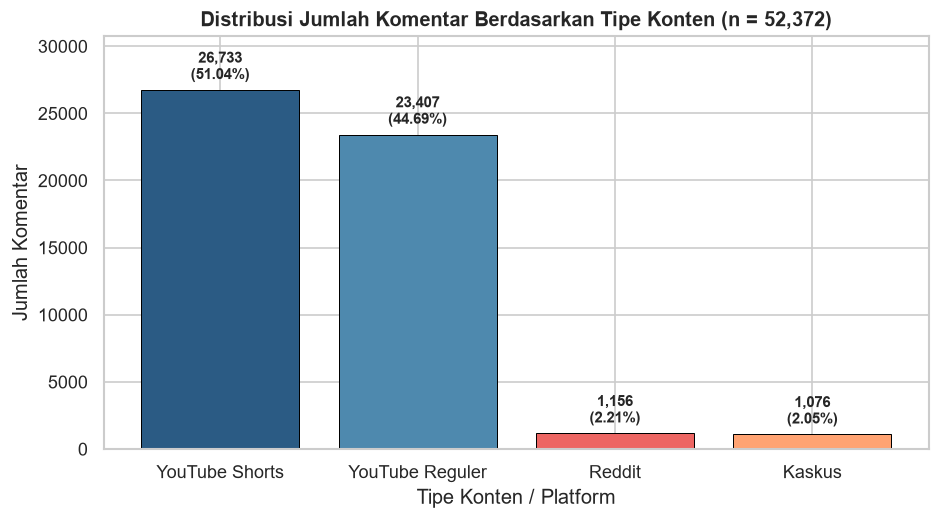

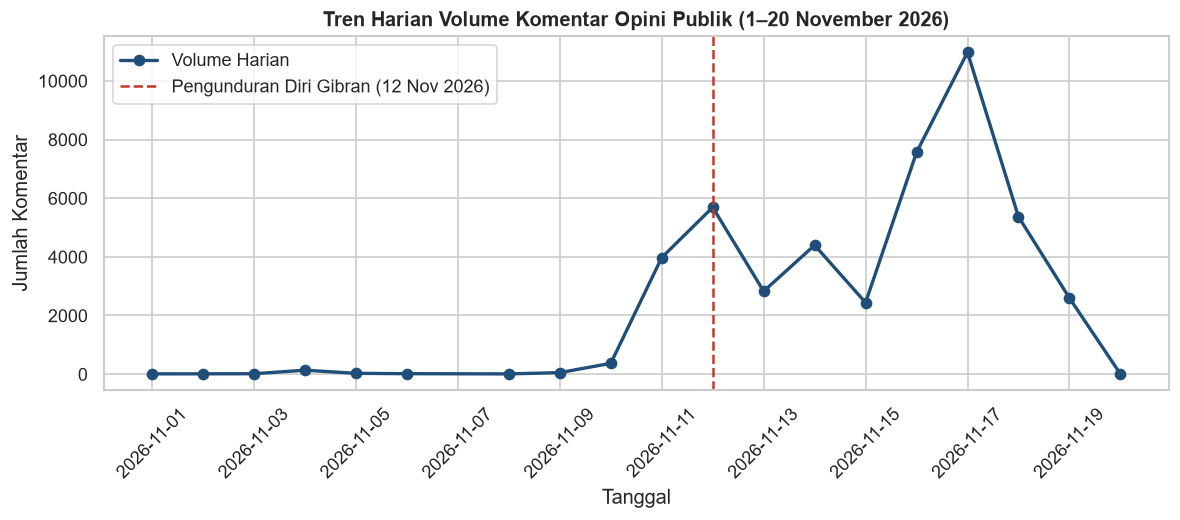

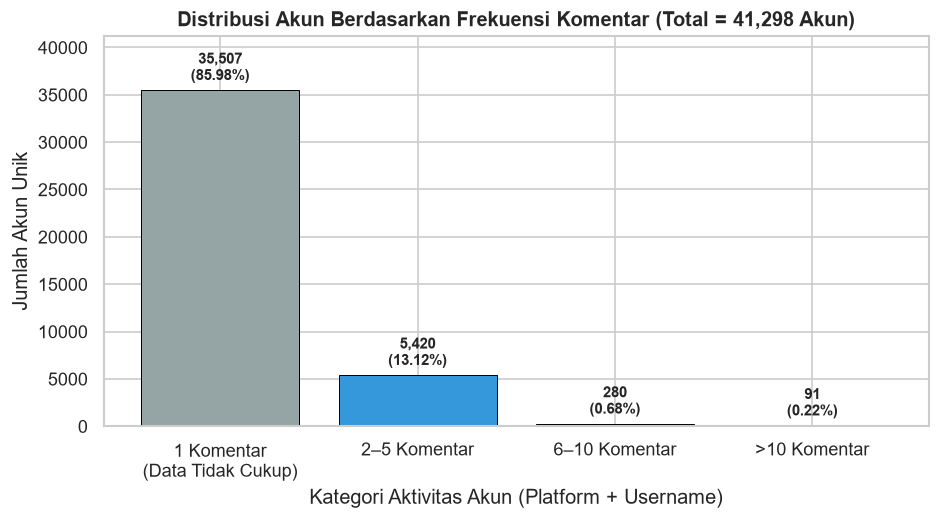

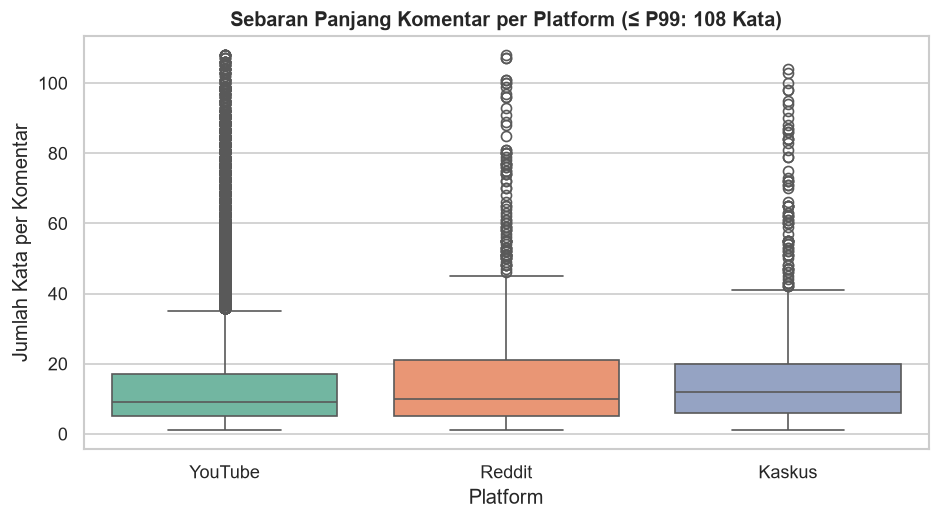

In [5]:
from pathlib import Path

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# --- GRAFIK 1: Distribusi Komentar per Tipe Konten ---
fig, ax = plt.subplots(figsize=(8, 4.5))
tipe_counts = df_eda["Tipe_Konten"].value_counts()
colors = ["#2B5B84", "#4E89AE", "#ED6663", "#FFA372"]

bars = ax.bar(tipe_counts.index, tipe_counts.values, color=colors, edgecolor="black", linewidth=0.6)
ax.set_title(f"Distribusi Jumlah Komentar Berdasarkan Tipe Konten (n = {len(df_eda):,})")
ax.set_xlabel("Tipe Konten / Platform")
ax.set_ylabel("Jumlah Komentar")
ax.set_ylim(0, tipe_counts.max() * 1.15)

for bar in bars:
    h = bar.get_height()
    pct = h / len(df_eda) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, h + 500, f"{h:,}\n({pct:.2f}%)",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_1_distribusi_platform.png", dpi=300)
plt.show()

# --- GRAFIK 2: Tren Harian Volume Komentar (November 2026) ---
nov_df = df_eda[df_eda["Tanggal_dt"] >= "2026-11-01"]
daily_nov = nov_df.groupby(nov_df["Tanggal_dt"].dt.date).size()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily_nov.index, daily_nov.values, marker="o", linewidth=2, color="#1F4E79", label="Volume Harian")
ax.axvline(pd.to_datetime("2026-11-12").date(), color="#C0392B", linestyle="--", linewidth=1.5,
           label="Pengunduran Diri Gibran (12 Nov 2026)")
ax.set_title("Tren Harian Volume Komentar Opini Publik (1–20 November 2026)")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Jumlah Komentar")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_2_tren_november_2026.png", dpi=300)
plt.show()

# --- GRAFIK 3: Segmentasi Frekuensi Aktivitas Akun ---
bins = [0, 1, 5, 10, acc_counts.max()]
labels = ["1 Komentar\n(Data Tidak Cukup)", "2–5 Komentar", "6–10 Komentar", ">10 Komentar"]
acc_binned = pd.cut(acc_counts, bins=bins, labels=labels).value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(acc_binned.index, acc_binned.values, color=["#95A5A6", "#3498DB", "#E67E22", "#E74C3C"],
              edgecolor="black", linewidth=0.6)
ax.set_title(f"Distribusi Akun Berdasarkan Frekuensi Komentar (Total = {len(acc_counts):,} Akun)")
ax.set_xlabel("Kategori Aktivitas Akun (Platform + Username)")
ax.set_ylabel("Jumlah Akun Unik")
ax.set_ylim(0, acc_binned.max() * 1.16)

for bar in bars:
    h = bar.get_height()
    pct = h / len(acc_counts) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, h + 600, f"{h:,}\n({pct:.2f}%)",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_3_aktivitas_akun.png", dpi=300)
plt.show()

# --- GRAFIK 4: Sebaran Panjang Komentar (Jumlah Kata) per Platform ---
p99_words = df_eda["Jumlah_Kata"].quantile(0.99)
df_plot_words = df_eda[df_eda["Jumlah_Kata"] <= p99_words]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df_plot_words, x="Platform", y="Jumlah_Kata", hue="Platform", palette="Set2", legend=False, ax=ax)
ax.set_title(f"Sebaran Panjang Komentar per Platform (≤ P99: {int(p99_words)} Kata)")
ax.set_xlabel("Platform")
ax.set_ylabel("Jumlah Kata per Komentar")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_4_panjang_komentar.png", dpi=300)
plt.show()

# Data Preperation

In [6]:
import re
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)

# Pastikan folder output tersedia
FIGURES_DIR = Path("figures")
ARTIFACTS_DIR = Path("artifacts")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# === 1. PEMBERSIHAN DATA BERURUTAN ===
df_clean = df_raw.copy()
cleaning_log = [("Data Mentah Awal", len(df_clean), 0)]

# (a) Hapus baris duplikat identik (seluruh 7 kolom sama)
prev = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
cleaning_log.append(("Hapus Duplikat Identik", len(df_clean), prev - len(df_clean)))

# (b) Hapus komentar kosong (NaN atau whitespace saja)
prev = len(df_clean)
mask_valid_text = df_clean["Komentar"].notna() & (df_clean["Komentar"].astype(str).str.strip() != "")
df_clean = df_clean[mask_valid_text].reset_index(drop=True)
cleaning_log.append(("Hapus Komentar Kosong (NaN)", len(df_clean), prev - len(df_clean)))

# (c) Hapus placeholder scraping Kaskus ('Username' / 'Isi Post')
prev = len(df_clean)
mask_placeholder = (df_clean["Platform"] == "Kaskus") & (
    (df_clean["Username"] == "Username") | (df_clean["Komentar"] == "Isi Post")
)
df_clean = df_clean[~mask_placeholder].reset_index(drop=True)
cleaning_log.append(("Hapus Placeholder Kaskus", len(df_clean), prev - len(df_clean)))

# (d) Hapus noise UI/sidebar Kaskus (thread rekomendasi berakhiran 'Bagikan')
prev = len(df_clean)
mask_kaskus_ui = (df_clean["Platform"] == "Kaskus") & (
    df_clean["Komentar"].astype(str).str.contains(r"Bagikan$", regex=True, na=False)
)
df_clean = df_clean[~mask_kaskus_ui].reset_index(drop=True)
cleaning_log.append(("Hapus Noise UI Kaskus ('Bagikan')", len(df_clean), prev - len(df_clean)))

# === 2. PARSING TANGGAL, JUMLAH_LIKE & NORMALISASI AKUN ===
df_clean["Tanggal_dt"] = pd.to_datetime(df_clean["Tanggal"], errors="coerce")

def parse_likes_clean(val):
    s = str(val).strip().lower().replace("\xa0", " ")
    if "rb" in s:
        return float(s.replace("rb", "").strip().replace(",", ".")) * 1000
    if "jt" in s:
        return float(s.replace("jt", "").strip().replace(",", ".")) * 1_000_000
    return pd.to_numeric(s, errors="coerce")

df_clean["Likes_Num"] = df_clean["Jumlah_Like"].apply(parse_likes_clean)

# Normalisasi prefix '@' pada Kaskus agar akun seperti '@albyabby91' & 'albyabby91' menyatu
df_clean["Username_Norm"] = df_clean["Username"].astype(str).str.strip()
mask_kaskus = df_clean["Platform"] == "Kaskus"
df_clean.loc[mask_kaskus, "Username_Norm"] = df_clean.loc[mask_kaskus, "Username_Norm"].str.lstrip("@")

# Kunci unit analisis Jalur A: Platform + Username_Norm
df_clean["Account_ID"] = df_clean["Platform"] + " | " + df_clean["Username_Norm"]

# Normalisasi ringan teks khusus untuk menghitung rasio duplikasi antar-komentar akun
df_clean["Komentar_Norm"] = (
    df_clean["Komentar"].astype(str).str.lower().str.strip().str.replace(r"\s+", " ", regex=True)
)
df_clean["Char_Len"] = df_clean["Komentar"].astype(str).str.len()
df_clean["Word_Len"] = df_clean["Komentar"].astype(str).str.split().str.len()

# Tampilkan log pembersihan
df_cleaning_log = pd.DataFrame(cleaning_log, columns=["Tahap_Pembersihan", "Sisa_Baris", "Baris_Dihapus"])
print("=== RINGKASAN LOG PEMBERSIHAN DATA ===")
display(df_cleaning_log)
print(f"Audit Likes Negatif (dipertahankan - Reddit): {(df_clean['Likes_Num'] < 0).sum()} baris")
print(f"Total Akun Unik (Platform + Username_Norm)  : {df_clean['Account_ID'].nunique():,} akun")

# Simpan dataset bersih untuk dipakai ulang di Jalur A & Jalur B
df_clean.to_csv(ARTIFACTS_DIR / "dataset_clean_master.csv", index=False)

=== RINGKASAN LOG PEMBERSIHAN DATA ===


,Tahap_Pembersihan,Sisa_Baris,Baris_Dihapus
0,Data Mentah Awal,52372,0
1,Hapus Duplikat Identik,52027,345
2,Hapus Komentar Kosong (NaN),52003,24
3,Hapus Placeholder Kaskus,51945,58
4,Hapus Noise UI Kaskus ('Bagikan'),51904,41


Audit Likes Negatif (dipertahankan - Reddit): 27 baris
Total Akun Unik (Platform + Username_Norm)  : 41,265 akun


In [7]:
def extract_account_features(df_input: pd.DataFrame) -> pd.DataFrame:
    """
    Mengekstrak 8 fitur perilaku pada unit analisis (Platform + Username_Norm).
    Fungsi ini dibuat modular agar dapat dipakai ulang pada prototype Streamlit (Menu 2).
    """
    data = df_input.copy()
    if "Tanggal_dt" not in data.columns:
        data["Tanggal_dt"] = pd.to_datetime(data["Tanggal"], errors="coerce")
    if "Username_Norm" not in data.columns:
        data["Username_Norm"] = data["Username"].astype(str).str.strip()
        m_k = data["Platform"] == "Kaskus"
        data.loc[m_k, "Username_Norm"] = data.loc[m_k, "Username_Norm"].str.lstrip("@")
    if "Account_ID" not in data.columns:
        data["Account_ID"] = data["Platform"].astype(str) + " | " + data["Username_Norm"].astype(str)
    if "Komentar_Norm" not in data.columns:
        data["Komentar_Norm"] = (
            data["Komentar"].astype(str).str.lower().str.strip().str.replace(r"\s+", " ", regex=True)
        )
    if "Char_Len" not in data.columns:
        data["Char_Len"] = data["Komentar"].astype(str).str.len()

    data_sorted = data.sort_values(["Account_ID", "Tanggal_dt"])
    records = []

    for acc_id, g in data_sorted.groupby("Account_ID", sort=False):
        n_comments = len(g)
        n_sources = g["Source_ID"].nunique()

        times = g["Tanggal_dt"].dropna().values
        if len(times) > 1:
            span_hours = float((times[-1] - times[0]) / np.timedelta64(1, "h"))
            diffs_sec = np.diff(times) / np.timedelta64(1, "s")
            mean_interval_hours = float(np.mean(diffs_sec)) / 3600.0
        else:
            span_hours = 0.0
            mean_interval_hours = 0.0

        # Frekuensi komentar per jam (batas bawah 1 jam untuk menghindari pembagian nol)
        freq_per_hour = n_comments / max(span_hours, 1.0)

        # Rasio duplikasi komentar akun: 0 = seluruh komentar unik, mendekati 1 = sangat repetitif
        n_unique_texts = g["Komentar_Norm"].nunique()
        dup_ratio = 1.0 - (n_unique_texts / n_comments)

        # Keragaman leksikal (Type-Token Ratio gabungan seluruh komentar akun)
        all_tokens = " ".join(g["Komentar_Norm"].tolist()).split()
        text_diversity = (len(set(all_tokens)) / len(all_tokens)) if len(all_tokens) > 0 else 0.0

        mean_char_len = float(g["Char_Len"].mean())

        records.append({
            "Account_ID": acc_id,
            "Platform": g["Platform"].iloc[0],
            "Username": g["Username_Norm"].iloc[0],
            "jumlah_komentar": n_comments,
            "jumlah_source_unik": n_sources,
            "rentang_aktivitas_jam": span_hours,
            "rata_interval_jam": mean_interval_hours,
            "frekuensi_per_jam": float(freq_per_hour),
            "rasio_duplikasi": float(dup_ratio),
            "rata_panjang_karakter": mean_char_len,
            "keragaman_teks": float(text_diversity),
        })

    return pd.DataFrame(records)

df_accounts_all = extract_account_features(df_clean)

# Filter kecukupan data Jalur A
df_accounts_all["Status_Kecukupan"] = np.where(
    df_accounts_all["jumlah_komentar"] == 1,
    "Data tidak cukup untuk dinilai",
    "Memenuhi syarat pemodelan (>1 komentar)"
)

df_acc_single = df_accounts_all[df_accounts_all["jumlah_komentar"] == 1].copy()
df_acc_model = df_accounts_all[df_accounts_all["jumlah_komentar"] > 1].copy().reset_index(drop=True)

print("=== PEMISAHAN UNIT ANALISIS JALUR A ===")
display(df_accounts_all["Status_Kecukupan"].value_counts().to_frame("Jumlah_Akun"))

FEATURE_COLS = [
    "jumlah_komentar",
    "jumlah_source_unik",
    "rentang_aktivitas_jam",
    "rata_interval_jam",
    "frekuensi_per_jam",
    "rasio_duplikasi",
    "rata_panjang_karakter",
    "keragaman_teks",
]

print(f"\nStatistik Deskriptif 8 Fitur Perilaku (n = {len(df_acc_model):,} akun):")
display(df_acc_model[FEATURE_COLS].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(3))

=== PEMISAHAN UNIT ANALISIS JALUR A ===


,Jumlah_Akun
Status_Kecukupan,
Data tidak cukup untuk dinilai,35584
Memenuhi syarat pemodelan (>1 komentar),5681



Statistik Deskriptif 8 Fitur Perilaku (n = 5,681 akun):


,jumlah_komentar,jumlah_source_unik,rentang_aktivitas_jam,rata_interval_jam,frekuensi_per_jam,rasio_duplikasi,rata_panjang_karakter,keragaman_teks
count,5681.000,5681.000,5681.000,5681.000,5681.000,5681.000,5681.000,5681.000
mean,2.873,1.409,180.370,112.665,1.692,0.006,114.448,0.876
std,3.044,0.902,1075.007,588.662,1.719,0.050,286.762,0.125
min,2.000,1.000,0.000,0.000,0.000,0.000,1.000,0.049
50%,2.000,1.000,0.000,0.000,2.000,0.000,74.500,0.902
75%,3.000,2.000,48.000,24.000,2.000,0.000,124.667,0.969
90%,4.000,2.000,120.000,96.000,3.000,0.000,205.143,1.000
95%,6.000,2.000,1320.000,696.000,4.000,0.000,275.500,1.000
99%,13.000,4.000,1429.200,1416.000,8.000,0.250,595.900,1.000
max,108.000,23.000,15618.166,13409.886,30.000,0.800,10035.625,1.000


# Training, Benchmarking & Evaluasi Jalur A (Penyaringan Akun)

In [8]:
SKEWED_COLS = [
    "jumlah_komentar",
    "jumlah_source_unik",
    "rentang_aktivitas_jam",
    "rata_interval_jam",
    "frekuensi_per_jam",
    "rata_panjang_karakter",
]
SKEWED_IDX = [FEATURE_COLS.index(c) for c in SKEWED_COLS]

def apply_log1p_selected(X):
    """Transformasi log1p hanya pada kolom berdistribusi right-skewed."""
    X_arr = np.asarray(X, dtype=float).copy()
    X_arr[:, SKEWED_IDX] = np.log1p(np.maximum(X_arr[:, SKEWED_IDX], 0.0))
    return X_arr

X_raw_arr = df_acc_model[FEATURE_COLS].values
X_log_arr = apply_log1p_selected(X_raw_arr)

# Bandingkan StandardScaler vs RobustScaler menggunakan K-Means (k=3) sebagai pembanding awal
scaler_bench = []
for s_name, s_obj in [("StandardScaler (log1p)", StandardScaler()), ("RobustScaler (log1p)", RobustScaler())]:
    X_tmp = s_obj.fit_transform(X_log_arr)
    lbl_tmp = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_tmp)
    scaler_bench.append({
        "Scaler": s_name,
        "Silhouette": silhouette_score(X_tmp, lbl_tmp),
        "Davies_Bouldin": davies_bouldin_score(X_tmp, lbl_tmp),
        "Calinski_Harabasz": calinski_harabasz_score(X_tmp, lbl_tmp),
    })

df_scaler_bench = pd.DataFrame(scaler_bench).round(4)
print("=== PERBANDINGAN SCALER (PEMBANDING AWAL K-MEANS k=3) ===")
display(df_scaler_bench)

# Pilih scaler dengan struktur pemisahan klaster lebih baik (StandardScaler + log1p)
selected_scaler = StandardScaler()
X_scaled = selected_scaler.fit_transform(X_log_arr)

=== PERBANDINGAN SCALER (PEMBANDING AWAL K-MEANS k=3) ===


,Scaler,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,StandardScaler (log1p),0.4833,0.8117,2966.1692
1,RobustScaler (log1p),0.4080,1.0101,2710.7311


=== HASIL EKSPERIMEN CLUSTERING k = 1 s.d. 10 ===


,k,KMeans_Inertia,KMeans_Silhouette,KMeans_DBI,KMeans_CH,Agg_Silhouette,BIRCH_Silhouette,GMM_BIC,GMM_AIC
0,1,45448.0000,NaN,NaN,NaN,NaN,NaN,81202.6554,80910.2806
1,2,27962.9008,0.4664,0.9894,3551.1055,0.4553,0.6743,-49595.5354,-50186.9300
2,3,22226.2036,0.4833,0.8117,2966.1692,0.4752,0.4817,-138548.8759,-139439.2901
3,4,18689.1118,0.3939,1.0535,2709.4244,0.3464,0.4870,-151016.8498,-152206.2838
4,5,16140.9024,0.3487,1.1726,2576.4931,0.3371,0.4806,-192858.6220,-194347.0756
5,6,14339.5773,0.3506,1.0714,2462.2804,0.2889,0.4245,-193217.4385,-195004.9119
6,7,13047.2730,0.3100,1.1738,2348.4178,0.2865,0.4252,-223926.8541,-226013.3472
7,8,12026.5424,0.3177,1.1376,2252.1626,0.2946,0.4240,-230079.1706,-232464.6835
8,9,11119.2490,0.3209,1.0957,2188.9144,0.2990,0.4022,-229537.9811,-232222.5137
9,10,10339.6744,0.2862,1.1198,2139.5430,0.2069,0.3913,-244879.0818,-247862.6341


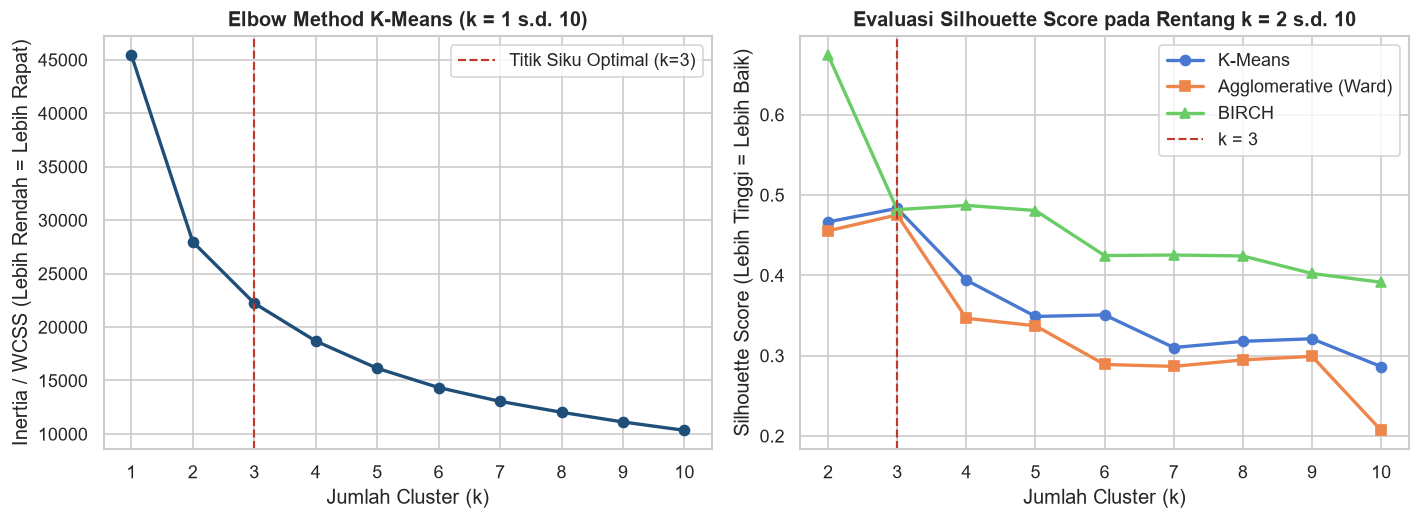

=== HYPERPARAMETER TUNING: ISOLATION FOREST ===


,n_estimators,contamination,Jumlah_Anomali,Rata_Komentar_Anomali,Rata_Duplikasi_Anomali,Rata_Keragaman_Anomali,Stabilitas_ARI
0,300,0.05,284,8.7641,0.1056,0.6416,0.9426
1,300,0.03,171,10.1520,0.1632,0.5738,0.9336
2,200,0.03,171,10.1813,0.1515,0.5829,0.9324
3,200,0.05,284,8.5352,0.1047,0.6419,0.9309
4,200,0.02,114,11.7456,0.1677,0.5500,0.9265
5,300,0.08,455,7.3626,0.0668,0.6901,0.9249
6,300,0.10,568,6.7482,0.0547,0.7124,0.9240
7,200,0.08,455,7.2286,0.0668,0.6932,0.9199
8,300,0.02,114,11.7895,0.1791,0.5282,0.9159
9,100,0.05,284,8.5141,0.1037,0.6362,0.9058


In [9]:
# === CELL EKSPERIMEN LENGKAP: SWEEP k = 1..10 & HYPERPARAMETER TUNING JALUR A ===
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

# 1. Eksperimen k = 1 s.d. 10 untuk K-Means, GMM, Agglomerative, dan BIRCH
k_range = range(1, 11)
exp_k_rows = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    gmm = GaussianMixture(n_components=k, random_state=42, n_init=5).fit(X_scaled)

    if k == 1:
        # Metrik jarak antar-cluster tidak terdefinisi untuk k=1
        exp_k_rows.append({
            "k": k,
            "KMeans_Inertia": km.inertia_,
            "KMeans_Silhouette": np.nan,
            "KMeans_DBI": np.nan,
            "KMeans_CH": np.nan,
            "Agg_Silhouette": np.nan,
            "BIRCH_Silhouette": np.nan,
            "GMM_BIC": gmm.bic(X_scaled),
            "GMM_AIC": gmm.aic(X_scaled),
        })
    else:
        km_lbl = km.labels_
        agg_lbl = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
        birch_lbl = Birch(n_clusters=k, threshold=0.5).fit_predict(X_scaled)

        exp_k_rows.append({
            "k": k,
            "KMeans_Inertia": km.inertia_,
            "KMeans_Silhouette": silhouette_score(X_scaled, km_lbl),
            "KMeans_DBI": davies_bouldin_score(X_scaled, km_lbl),
            "KMeans_CH": calinski_harabasz_score(X_scaled, km_lbl),
            "Agg_Silhouette": silhouette_score(X_scaled, agg_lbl),
            "BIRCH_Silhouette": silhouette_score(X_scaled, birch_lbl),
            "GMM_BIC": gmm.bic(X_scaled),
            "GMM_AIC": gmm.aic(X_scaled),
        })

df_exp_k1_10 = pd.DataFrame(exp_k_rows).round(4)
print("=== HASIL EKSPERIMEN CLUSTERING k = 1 s.d. 10 ===")
display(df_exp_k1_10)

# 2. Visualisasi Kurva Elbow (k=1..10) & Perbandingan Silhouette (k=2..10)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Subplot 1: Elbow Method (Inertia k=1..10)
axes[0].plot(df_exp_k1_10["k"], df_exp_k1_10["KMeans_Inertia"], marker="o", linewidth=2, color="#1F4E79")
axes[0].axvline(3, color="#C0392B", linestyle="--", linewidth=1.3, label="Titik Siku Optimal (k=3)")
axes[0].set_title("Elbow Method K-Means (k = 1 s.d. 10)")
axes[0].set_xlabel("Jumlah Cluster (k)")
axes[0].set_ylabel("Inertia / WCSS (Lebih Rendah = Lebih Rapat)")
axes[0].set_xticks(range(1, 11))
axes[0].legend()

# Subplot 2: Kurva Silhouette Score (k=2..10)
df_k2_10 = df_exp_k1_10[df_exp_k1_10["k"] >= 2]
axes[1].plot(df_k2_10["k"], df_k2_10["KMeans_Silhouette"], marker="o", linewidth=2, label="K-Means")
axes[1].plot(df_k2_10["k"], df_k2_10["Agg_Silhouette"], marker="s", linewidth=2, label="Agglomerative (Ward)")
axes[1].plot(df_k2_10["k"], df_k2_10["BIRCH_Silhouette"], marker="^", linewidth=2, label="BIRCH")
axes[1].axvline(3, color="#C0392B", linestyle="--", linewidth=1.3, label="k = 3")
axes[1].set_title("Evaluasi Silhouette Score pada Rentang k = 2 s.d. 10")
axes[1].set_xlabel("Jumlah Cluster (k)")
axes[1].set_ylabel("Silhouette Score (Lebih Tinggi = Lebih Baik)")
axes[1].set_xticks(range(2, 11))
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "jalurA_elbow_dan_silhouette_k1_10.png", dpi=300)
plt.show()

# 3. Hyperparameter Tuning Grid untuk Isolation Forest (n_estimators x contamination)
if_tuning_rows = []
rng_tune = np.random.default_rng(42)
sub_indices = [rng_tune.choice(len(X_scaled), size=int(len(X_scaled) * 0.8), replace=False) for _ in range(3)]

for n_est in [100, 200, 300]:
    for cont in [0.02, 0.03, 0.05, 0.08, 0.10]:
        iso = IsolationForest(n_estimators=n_est, contamination=cont, random_state=42)
        pred_full = iso.fit_predict(X_scaled)
        anom_mask = pred_full == -1

        # Uji konsistensi/stabilitas ARI pada 3 subsample 80%
        aris = []
        for idx in sub_indices:
            sub_pred = IsolationForest(n_estimators=n_est, contamination=cont, random_state=42).fit_predict(X_scaled[idx])
            aris.append(adjusted_rand_score(pred_full[idx], sub_pred))

        if_tuning_rows.append({
            "n_estimators": n_est,
            "contamination": cont,
            "Jumlah_Anomali": int(anom_mask.sum()),
            "Rata_Komentar_Anomali": df_acc_model.loc[anom_mask, "jumlah_komentar"].mean(),
            "Rata_Duplikasi_Anomali": df_acc_model.loc[anom_mask, "rasio_duplikasi"].mean(),
            "Rata_Keragaman_Anomali": df_acc_model.loc[anom_mask, "keragaman_teks"].mean(),
            "Stabilitas_ARI": float(np.mean(aris)),
        })

df_if_tuning = pd.DataFrame(if_tuning_rows).round(4)
print("=== HYPERPARAMETER TUNING: ISOLATION FOREST ===")
display(df_if_tuning.sort_values("Stabilitas_ARI", ascending=False).reset_index(drop=True))

In [10]:
# === 1. BENCHMARKING 5 ALGORITMA CLUSTERING ===
clustering_results = []

# K-Means, Agglomerative, GMM, BIRCH (k = 2, 3, 4)
for k in [2, 3, 4]:
    candidates = [
        (f"K-Means (k={k})", KMeans(n_clusters=k, random_state=42, n_init=10), True),
        (f"Agglomerative (k={k})", AgglomerativeClustering(n_clusters=k, linkage="ward"), False),
        (f"GMM (k={k})", GaussianMixture(n_components=k, random_state=42, n_init=5), True),
        (f"BIRCH (k={k})", Birch(n_clusters=k, threshold=0.5), True),
    ]
    for name, model, can_predict in candidates:
        lbl = model.fit_predict(X_scaled)
        counts = np.bincount(lbl)
        clustering_results.append({
            "Model": name,
            "Jml_Cluster": k,
            "Jml_Noise": 0,
            "Silhouette": silhouette_score(X_scaled, lbl),
            "Davies_Bouldin": davies_bouldin_score(X_scaled, lbl),
            "Calinski_Harabasz": calinski_harabasz_score(X_scaled, lbl),
            "Porsi_Cluster_Terkecil (%)": (counts.min() / len(lbl)) * 100,
            "Dukung_Predict_Baru": can_predict,
        })

# DBSCAN (variasi eps & min_samples)
for eps in [1.0, 1.5, 2.0, 2.5]:
    for ms in [10, 20]:
        lbl = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_noise = int((lbl == -1).sum())
        n_clusters = len(set(lbl)) - (1 if -1 in lbl else 0)
        if n_clusters >= 2:
            mask_non_noise = lbl != -1
            sil = silhouette_score(X_scaled[mask_non_noise], lbl[mask_non_noise])
            dbi = davies_bouldin_score(X_scaled[mask_non_noise], lbl[mask_non_noise])
            ch = calinski_harabasz_score(X_scaled[mask_non_noise], lbl[mask_non_noise])
        else:
            sil, dbi, ch = np.nan, np.nan, np.nan

        clustering_results.append({
            "Model": f"DBSCAN (eps={eps}, ms={ms})",
            "Jml_Cluster": n_clusters,
            "Jml_Noise": n_noise,
            "Silhouette": sil,
            "Davies_Bouldin": dbi,
            "Calinski_Harabasz": ch,
            "Porsi_Cluster_Terkecil (%)": (n_noise / len(lbl)) * 100,
            "Dukung_Predict_Baru": False,
        })

df_cluster_bench = pd.DataFrame(clustering_results).round(4)
print("=== TABEL BENCHMARKING 5 ALGORITMA CLUSTERING ===")
display(df_cluster_bench.sort_values("Silhouette", ascending=False).reset_index(drop=True))

# === 2. UJI STABILITAS MODEL (5x 80% SUBSAMPLE ARI) ===
def eval_subsample_stability(model_fn, X, n_runs=5, sample_frac=0.8, seed=42):
    full_labels = model_fn(X)
    rng = np.random.default_rng(seed)
    aris = []
    n = len(X)
    for _ in range(n_runs):
        idx = rng.choice(n, size=int(n * sample_frac), replace=False)
        sub_labels = model_fn(X[idx])
        aris.append(adjusted_rand_score(full_labels[idx], sub_labels))
    return float(np.mean(aris)), float(np.std(aris))

stability_candidates = {
    "K-Means (k=3)": lambda X: KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X),
    "Agglomerative (k=3)": lambda X: AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X),
    "GMM (k=3)": lambda X: GaussianMixture(n_components=3, random_state=42, n_init=5).fit_predict(X),
    "BIRCH (k=2)": lambda X: Birch(n_clusters=2, threshold=0.5).fit_predict(X),
    "BIRCH (k=3)": lambda X: Birch(n_clusters=3, threshold=0.5).fit_predict(X),
    "DBSCAN (eps=2.0, ms=10)": lambda X: DBSCAN(eps=2.0, min_samples=10).fit_predict(X),
    "Isolation Forest (5%)": lambda X: IsolationForest(n_estimators=200, contamination=0.05, random_state=42).fit_predict(X),
    "LOF (k=20, 5%)": lambda X: LocalOutlierFactor(n_neighbors=20, contamination=0.05).fit_predict(X),
}

stab_rows = []
for m_name, fn in stability_candidates.items():
    mean_ari, std_ari = eval_subsample_stability(fn, X_scaled)
    stab_rows.append({"Model": m_name, "Stabilitas_ARI_Mean": mean_ari, "Stabilitas_ARI_Std": std_ari})

df_stability = pd.DataFrame(stab_rows).round(4).sort_values("Stabilitas_ARI_Mean", ascending=False)
print("\n=== UJI STABILITAS CLUSTER & ANOMALI (SUBSAMPLE ARI, 5 RUNS) ===")
display(df_stability.reset_index(drop=True))

=== TABEL BENCHMARKING 5 ALGORITMA CLUSTERING ===


,Model,Jml_Cluster,Jml_Noise,Silhouette,Davies_Bouldin,Calinski_Harabasz,Porsi_Cluster_Terkecil (%),Dukung_Predict_Baru
0,"DBSCAN (eps=2.0, ms=10)",2,78,0.7094,0.3472,434.5153,1.3730,False
1,"DBSCAN (eps=2.0, ms=20)",2,93,0.7091,0.3232,350.3022,1.6370,False
2,"DBSCAN (eps=2.5, ms=20)",2,70,0.7090,0.3518,448.5346,1.2322,False
3,"DBSCAN (eps=2.5, ms=10)",2,68,0.7087,0.3520,447.2405,1.1970,False
4,BIRCH (k=2),2,0,0.6743,0.6608,819.6947,1.1970,True
5,BIRCH (k=4),4,0,0.4870,1.0305,2447.1845,1.1970,True
6,K-Means (k=3),3,0,0.4833,0.8117,2966.1692,1.1442,True
7,BIRCH (k=3),3,0,0.4817,0.8292,2900.5202,1.1970,True
8,Agglomerative (k=3),3,0,0.4752,0.7981,2815.9976,1.1442,False
9,K-Means (k=2),2,0,0.4664,0.9894,3551.1055,35.2931,True



=== UJI STABILITAS CLUSTER & ANOMALI (SUBSAMPLE ARI, 5 RUNS) ===


,Model,Stabilitas_ARI_Mean,Stabilitas_ARI_Std
0,K-Means (k=3),0.9982,0.0019
1,GMM (k=3),0.9978,0.0037
2,"DBSCAN (eps=2.0, ms=10)",0.9778,0.0093
3,BIRCH (k=3),0.9712,0.0306
4,BIRCH (k=2),0.9659,0.0203
5,Agglomerative (k=3),0.9362,0.0297
6,Isolation Forest (5%),0.9263,0.0070
7,"LOF (k=20, 5%)",0.7928,0.0184


In [11]:
# === 1. FIT MODEL ANOMALY DETECTION & KANDIDAT CLUSTERING UTAMA ===
iso_model = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)
iso_pred = iso_model.fit_predict(X_scaled)          # -1 = anomali, 1 = normal
iso_score = -iso_model.decision_function(X_scaled)  # makin tinggi = makin mencurigakan

lof_model = LocalOutlierFactor(n_neighbors=20, contamination=0.05, novelty=False)
lof_pred = lof_model.fit_predict(X_scaled)
lof_score = -lof_model.negative_outlier_factor_

km3_model = KMeans(n_clusters=3, random_state=42, n_init=10)
km3_lbl = km3_model.fit_predict(X_scaled)

birch2_model = Birch(n_clusters=2, threshold=0.5)
birch2_lbl = birch2_model.fit_predict(X_scaled)

db2_lbl = DBSCAN(eps=2.0, min_samples=10).fit_predict(X_scaled)

# Gabungkan hasil ke tabel evaluasi akun
df_eval_acc = df_acc_model.copy()
df_eval_acc["KMeans_k3"] = km3_lbl
df_eval_acc["BIRCH_k2"] = birch2_lbl
df_eval_acc["DBSCAN_Noise"] = (db2_lbl == -1).astype(int)
df_eval_acc["IF_Anomali"] = (iso_pred == -1).astype(int)
df_eval_acc["IF_Score"] = iso_score
df_eval_acc["LOF_Anomali"] = (lof_pred == -1).astype(int)
df_eval_acc["LOF_Score"] = lof_score

# Identifikasi ID cluster dengan rasio duplikasi tertinggi pada K-Means (k=3) & BIRCH (k=2)
km_dup_cluster = df_eval_acc.groupby("KMeans_k3")["rasio_duplikasi"].mean().idxmax()
birch_dup_cluster = df_eval_acc.groupby("BIRCH_k2")["rasio_duplikasi"].mean().idxmax()

df_eval_acc["KMeans_Repetitif"] = (df_eval_acc["KMeans_k3"] == km_dup_cluster).astype(int)
df_eval_acc["BIRCH_Repetitif"] = (df_eval_acc["BIRCH_k2"] == birch_dup_cluster).astype(int)

# Skor konsensus lintas metode (0 s.d. 4 sinyal kecurigaan)
df_eval_acc["Skor_Konsensus_Anomali"] = (
    df_eval_acc["IF_Anomali"]
    + df_eval_acc["LOF_Anomali"]
    + df_eval_acc["DBSCAN_Noise"]
    + df_eval_acc["KMeans_Repetitif"]
)

# === 2. PROFIL RATA-RATA FITUR ===
print("=== PROFIL CLUSTER: K-MEANS (k=3) ===")
display(df_eval_acc.groupby("KMeans_k3")[FEATURE_COLS].mean().round(3).assign(Jumlah_Akun=df_eval_acc["KMeans_k3"].value_counts()))

print("\n=== PROFIL ANOMALY DETECTION: ISOLATION FOREST (1 = Terindikasi Anomali) ===")
display(df_eval_acc.groupby("IF_Anomali")[FEATURE_COLS].mean().round(3).assign(Jumlah_Akun=df_eval_acc["IF_Anomali"].value_counts()))

print("\n=== PROFIL ANOMALY DETECTION: LOF (1 = Terindikasi Anomali) ===")
display(df_eval_acc.groupby("LOF_Anomali")[FEATURE_COLS].mean().round(3).assign(Jumlah_Akun=df_eval_acc["LOF_Anomali"].value_counts()))

overlap_if_lof = ((df_eval_acc["IF_Anomali"] == 1) & (df_eval_acc["LOF_Anomali"] == 1)).sum()
print(f"\nIrisan Akun Terindikasi Anomali (IF ∩ LOF): {overlap_if_lof} akun "
      f"({overlap_if_lof / df_eval_acc['IF_Anomali'].sum() * 100:.1f}% dari total anomali IF)")

# === 3. SIAPKAN & EKSPOR SAMPEL AUDIT MANUAL (TOP 30 AKUN MENCURIGAKAN) ===
# Ambil contoh 3 komentar dari masing-masing akun untuk memudahkan audit manual
sample_comments = (
    df_clean.groupby("Account_ID")["Komentar"]
    .apply(lambda s: " || ".join(s.astype(str).head(3).str.slice(0, 100)))
    .to_dict()
)

df_audit_top30 = (
    df_eval_acc.sort_values(["Skor_Konsensus_Anomali", "IF_Score"], ascending=[False, False])
    .head(30)
    .copy()
)
df_audit_top30["Contoh_Komentar"] = df_audit_top30["Account_ID"].map(sample_comments)
df_audit_top30["Hasil_Audit_Manual"] = ""  # Isi manual: Terindikasi Bot / Akun Aktif Organik / Ragu-ragu
df_audit_top30["Catatan_Auditor"] = ""

cols_audit = [
    "Account_ID", "Platform", "Username", "jumlah_komentar", "jumlah_source_unik",
    "frekuensi_per_jam", "rasio_duplikasi", "keragaman_teks", "IF_Score",
    "IF_Anomali", "LOF_Anomali", "DBSCAN_Noise", "KMeans_Repetitif",
    "Skor_Konsensus_Anomali", "Contoh_Komentar", "Hasil_Audit_Manual", "Catatan_Auditor"
]
df_audit_top30[cols_audit].to_csv(ARTIFACTS_DIR / "audit_manual_akun_jalurA.csv", index=False)

print("\n=== TOP 15 SAMPEL AKUN TERINDIKASI MENCURIGAKAN (UNTUK AUDIT MANUAL) ===")
display(df_audit_top30[cols_audit[:14]].head(15).round(3))
print(f"File audit manual tersimpan di: {ARTIFACTS_DIR / 'audit_manual_akun_jalurA.csv'}")

=== PROFIL CLUSTER: K-MEANS (k=3) ===


,jumlah_komentar,jumlah_source_unik,rentang_aktivitas_jam,rata_interval_jam,frekuensi_per_jam,rasio_duplikasi,rata_panjang_karakter,keragaman_teks,Jumlah_Akun
KMeans_k3,,,,,,,,,
0,2.623,1.050,0.079,0.034,2.578,0.000,104.065,0.880,3629
1,3.297,2.066,514.935,321.757,0.064,0.001,132.766,0.882,1987
2,3.815,1.415,18.723,9.176,2.044,0.449,134.185,0.449,65



=== PROFIL ANOMALY DETECTION: ISOLATION FOREST (1 = Terindikasi Anomali) ===


,jumlah_komentar,jumlah_source_unik,rentang_aktivitas_jam,rata_interval_jam,frekuensi_per_jam,rasio_duplikasi,rata_panjang_karakter,keragaman_teks,Jumlah_Akun
IF_Anomali,,,,,,,,,
0,2.575,1.334,85.449,77.683,1.678,0.000,98.904,0.888,5397
1,8.535,2.838,1984.194,777.451,1.972,0.105,409.837,0.642,284



=== PROFIL ANOMALY DETECTION: LOF (1 = Terindikasi Anomali) ===


,jumlah_komentar,jumlah_source_unik,rentang_aktivitas_jam,rata_interval_jam,frekuensi_per_jam,rasio_duplikasi,rata_panjang_karakter,keragaman_teks,Jumlah_Akun
LOF_Anomali,,,,,,,,,
0,2.718,1.374,133.866,87.245,1.675,0.004,100.924,0.881,5397
1,5.810,2.077,1064.101,595.734,2.011,0.033,371.459,0.772,284



Irisan Akun Terindikasi Anomali (IF ∩ LOF): 99 akun (34.9% dari total anomali IF)

=== TOP 15 SAMPEL AKUN TERINDIKASI MENCURIGAKAN (UNTUK AUDIT MANUAL) ===


,Account_ID,Platform,Username,jumlah_komentar,jumlah_source_unik,frekuensi_per_jam,rasio_duplikasi,keragaman_teks,IF_Score,IF_Anomali,LOF_Anomali,DBSCAN_Noise,KMeans_Repetitif,Skor_Konsensus_Anomali
135,Reddit | AutoModerator,Reddit,AutoModerator,6,6,0.028,0.500,0.305,0.179,1,1,1,1,4
1013,YouTube | @Fay_Har,YouTube,@Fay_Har,8,1,8.000,0.750,0.158,0.152,1,1,1,1,4
1429,YouTube | @KritoGurta,YouTube,@KritoGurta,16,1,0.667,0.188,0.264,0.130,1,1,1,1,4
3920,YouTube | @johonan3310,YouTube,@johonan3310,22,1,0.917,0.182,0.400,0.127,1,1,1,1,4
2908,YouTube | @barbaresport8466,YouTube,@barbaresport8466,3,1,0.125,0.667,0.286,0.123,1,1,1,1,4
3313,YouTube | @efef8344,YouTube,@efef8344,14,1,0.583,0.214,0.327,0.123,1,1,1,1,4
2569,YouTube | @ahmadrivandi153,YouTube,@ahmadrivandi153,5,1,5.000,0.800,0.137,0.121,1,1,1,1,4
1400,YouTube | @KevinTejakusumaa,YouTube,@KevinTejakusumaa,6,2,0.050,0.500,0.362,0.115,1,1,1,1,4
2359,YouTube | @YangTerlupakan373,YouTube,@YangTerlupakan373,3,1,3.000,0.667,0.333,0.106,1,1,1,1,4
1834,YouTube | @Q124-c2i,YouTube,@Q124-c2i,2,2,0.042,0.500,0.500,0.104,1,1,1,1,4


File audit manual tersimpan di: artifacts\audit_manual_akun_jalurA.csv


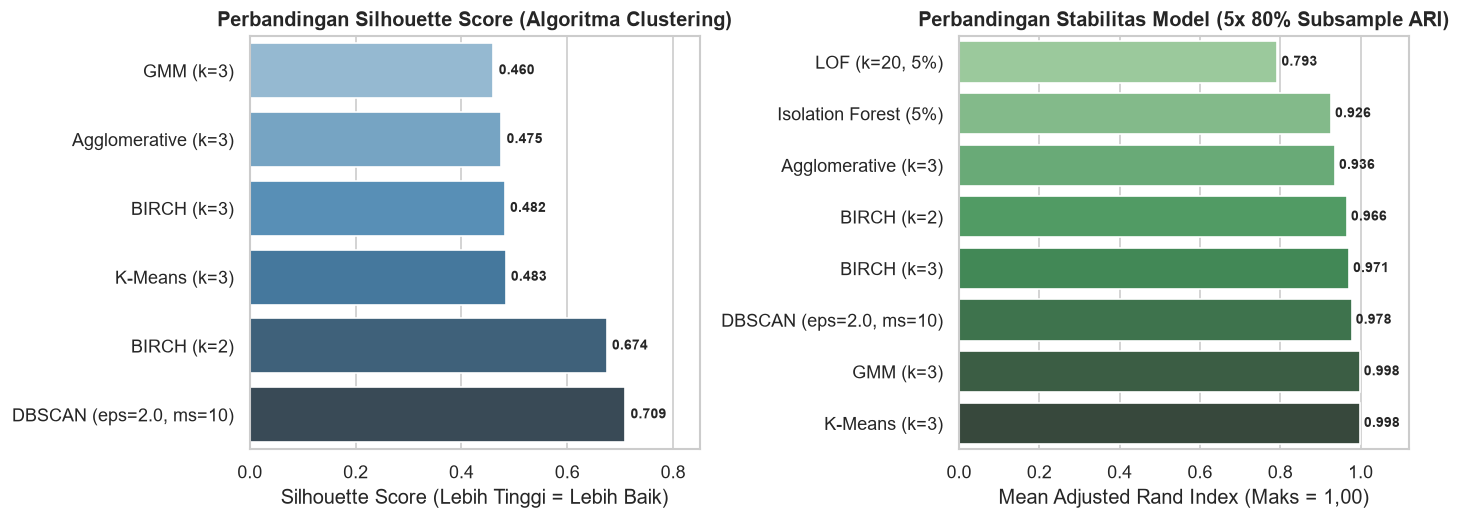

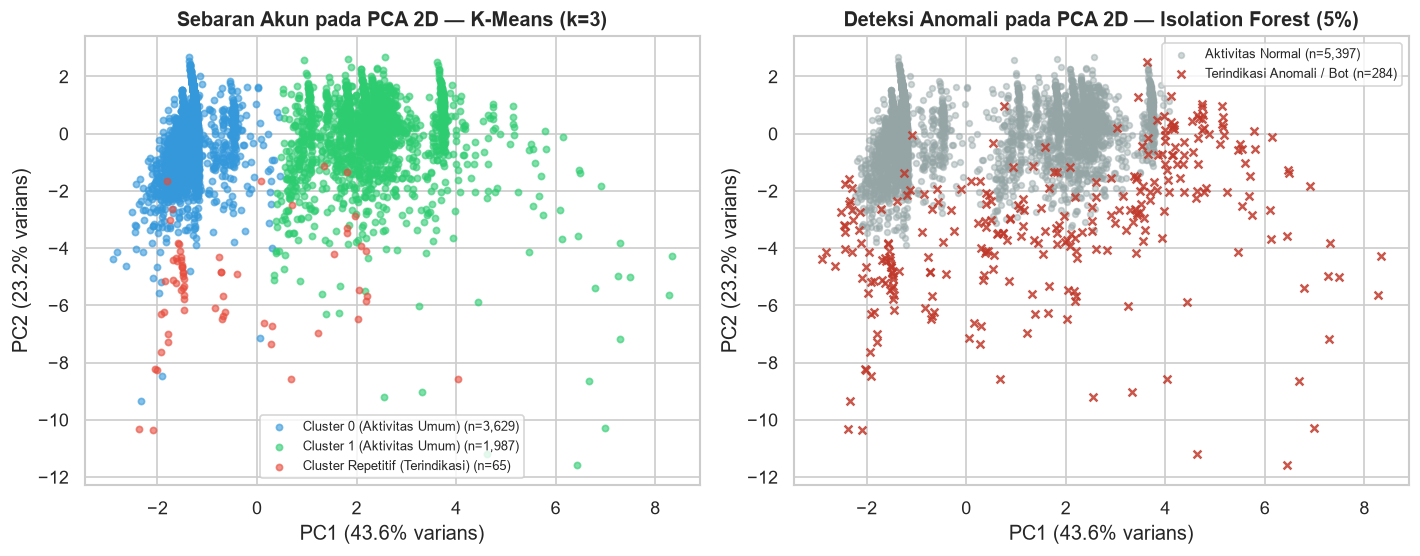

In [12]:
# --- GRAFIK JALUR A-1: Perbandingan Silhouette Score & Stabilitas ARI ---
top_models_plot = df_cluster_bench[
    df_cluster_bench["Model"].isin([
        "K-Means (k=3)", "Agglomerative (k=3)", "GMM (k=3)",
        "BIRCH (k=2)", "BIRCH (k=3)", "DBSCAN (eps=2.0, ms=10)"
    ])
].merge(df_stability, on="Model", how="left")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Subplot kiri: Silhouette Score
sns.barplot(data=top_models_plot.sort_values("Silhouette", ascending=True),
            y="Model", x="Silhouette", hue="Model", palette="Blues_d", legend=False, ax=axes[0])
axes[0].set_title("Perbandingan Silhouette Score (Algoritma Clustering)")
axes[0].set_xlabel("Silhouette Score (Lebih Tinggi = Lebih Baik)")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 0.85)
for p in axes[0].patches:
    w = p.get_width()
    axes[0].text(w + 0.01, p.get_y() + p.get_height()/2, f"{w:.3f}", va="center", fontsize=8.5, fontweight="bold")

# Subplot kanan: Stabilitas Subsample ARI (Clustering + Anomaly Detection)
sns.barplot(data=df_stability.sort_values("Stabilitas_ARI_Mean", ascending=True),
            y="Model", x="Stabilitas_ARI_Mean", hue="Model", palette="Greens_d", legend=False, ax=axes[1])
axes[1].set_title("Perbandingan Stabilitas Model (5x 80% Subsample ARI)")
axes[1].set_xlabel("Mean Adjusted Rand Index (Maks = 1,00)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 1.12)
for p in axes[1].patches:
    w = p.get_width()
    axes[1].text(w + 0.01, p.get_y() + p.get_height()/2, f"{w:.3f}", va="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "jalurA_1_benchmark_stabilitas.png", dpi=300)
plt.show()

# --- GRAFIK JALUR A-2: Proyeksi PCA 2D (K-Means k=3 vs Isolation Forest) ---
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
var_ratio = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Kiri: K-Means (k=3)
palette_km = {0: "#3498DB", 1: "#2ECC71", 2: "#E74C3C"}
for cid in sorted(df_eval_acc["KMeans_k3"].unique()):
    mask = df_eval_acc["KMeans_k3"] == cid
    tag = "Cluster Repetitif (Terindikasi)" if cid == km_dup_cluster else f"Cluster {cid} (Aktivitas Umum)"
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=14, alpha=0.6,
                    label=f"{tag} (n={mask.sum():,})", color=palette_km.get(cid, "#7F8C8D"))
axes[0].set_title("Sebaran Akun pada PCA 2D — K-Means (k=3)")
axes[0].set_xlabel(f"PC1 ({var_ratio[0]:.1f}% varians)")
axes[0].set_ylabel(f"PC2 ({var_ratio[1]:.1f}% varians)")
axes[0].legend(fontsize=8)

# Kanan: Isolation Forest (5%)
mask_norm = df_eval_acc["IF_Anomali"] == 0
mask_anom = df_eval_acc["IF_Anomali"] == 1
axes[1].scatter(X_pca[mask_norm, 0], X_pca[mask_norm, 1], s=12, alpha=0.45,
                color="#95A5A6", label=f"Aktivitas Normal (n={mask_norm.sum():,})")
axes[1].scatter(X_pca[mask_anom, 0], X_pca[mask_anom, 1], s=22, alpha=0.85,
                color="#C0392B", marker="x", label=f"Terindikasi Anomali / Bot (n={mask_anom.sum():,})")
axes[1].set_title("Deteksi Anomali pada PCA 2D — Isolation Forest (5%)")
axes[1].set_xlabel(f"PC1 ({var_ratio[0]:.1f}% varians)")
axes[1].set_ylabel(f"PC2 ({var_ratio[1]:.1f}% varians)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "jalurA_2_pca_perbandingan.png", dpi=300)
plt.show()

# Persiapan Sampel Anotasi & Jalur B

In [13]:
# === CELL 12: RINGKASAN BER-HIGHLIGHT & EKSPOR ARTEFAK JALUR A ===
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest

DATA_DIR = Path(r"C:\Users\agape\Documents\kuliah\Tahun 3 Ganjil\Data Science of Is\TA\Ketentuan")
RAW_FILE = DATA_DIR / "Data Scraping Opini Publik.csv"
ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Pastikan df_clean tersedia di memori (otomatis muat jika kernel restart)
if "df_clean" not in globals():
    clean_cache = ARTIFACTS_DIR / "dataset_clean_master.csv"
    if clean_cache.exists():
        df_clean = pd.read_csv(clean_cache)
    else:
        df_tmp = pd.read_csv(RAW_FILE).drop_duplicates().reset_index(drop=True)
        df_tmp = df_tmp[df_tmp["Komentar"].notna() & (df_tmp["Komentar"].astype(str).str.strip() != "")].reset_index(drop=True)
        df_tmp = df_tmp[~((df_tmp["Platform"] == "Kaskus") & ((df_tmp["Username"] == "Username") | (df_tmp["Komentar"] == "Isi Post")))].reset_index(drop=True)
        df_tmp = df_tmp[~((df_tmp["Platform"] == "Kaskus") & (df_tmp["Komentar"].astype(str).str.contains(r"Bagikan$", regex=True, na=False)))].reset_index(drop=True)
        df_tmp["Tanggal_dt"] = pd.to_datetime(df_tmp["Tanggal"], errors="coerce")
        df_tmp["Username_Norm"] = df_tmp["Username"].astype(str).str.strip()
        df_tmp.loc[df_tmp["Platform"] == "Kaskus", "Username_Norm"] = df_tmp.loc[df_tmp["Platform"] == "Kaskus", "Username_Norm"].str.lstrip("@")
        df_tmp["Account_ID"] = df_tmp["Platform"] + " | " + df_tmp["Username_Norm"]
        df_tmp["Komentar_Norm"] = df_tmp["Komentar"].astype(str).str.lower().str.strip().str.replace(r"\s+", " ", regex=True)
        df_tmp["Char_Len"] = df_tmp["Komentar"].astype(str).str.len()
        df_clean = df_tmp
        df_clean.to_csv(clean_cache, index=False)

# 2. Pastikan fitur akun & X_scaled tersedia di memori
FEATURE_COLS = [
    "jumlah_komentar", "jumlah_source_unik", "rentang_aktivitas_jam",
    "rata_interval_jam", "frekuensi_per_jam", "rasio_duplikasi",
    "rata_panjang_karakter", "keragaman_teks"
]
SKEWED_COLS = [
    "jumlah_komentar", "jumlah_source_unik", "rentang_aktivitas_jam",
    "rata_interval_jam", "frekuensi_per_jam", "rata_panjang_karakter"
]
SKEWED_IDX = [FEATURE_COLS.index(c) for c in SKEWED_COLS]

if "df_acc_model" not in globals() or "X_scaled" not in globals():
    df_clean["Tanggal_dt"] = pd.to_datetime(df_clean["Tanggal"], errors="coerce")
    data_sorted = df_clean.sort_values(["Account_ID", "Tanggal_dt"])
    records = []
    for acc_id, g in data_sorted.groupby("Account_ID", sort=False):
        n_comments = len(g)
        n_sources = g["Source_ID"].nunique()
        times = g["Tanggal_dt"].dropna().values
        if len(times) > 1:
            span_hours = float((times[-1] - times[0]) / np.timedelta64(1, "h"))
            diffs_sec = np.diff(times) / np.timedelta64(1, "s")
            mean_interval_hours = float(np.mean(diffs_sec)) / 3600.0
        else:
            span_hours = 0.0
            mean_interval_hours = 0.0
        freq_per_hour = n_comments / max(span_hours, 1.0)
        dup_ratio = 1.0 - (g["Komentar_Norm"].nunique() / n_comments)
        all_tokens = " ".join(g["Komentar_Norm"].tolist()).split()
        text_diversity = (len(set(all_tokens)) / len(all_tokens)) if len(all_tokens) > 0 else 0.0
        records.append({
            "Account_ID": acc_id,
            "Platform": g["Platform"].iloc[0],
            "Username": g["Username_Norm"].iloc[0],
            "jumlah_komentar": n_comments,
            "jumlah_source_unik": n_sources,
            "rentang_aktivitas_jam": span_hours,
            "rata_interval_jam": mean_interval_hours,
            "frekuensi_per_jam": float(freq_per_hour),
            "rasio_duplikasi": float(dup_ratio),
            "rata_panjang_karakter": float(g["Char_Len"].mean()),
            "keragaman_teks": float(text_diversity),
        })
    df_accounts_all = pd.DataFrame(records)
    df_acc_model = df_accounts_all[df_accounts_all["jumlah_komentar"] > 1].copy().reset_index(drop=True)

X_log_arr = df_acc_model[FEATURE_COLS].values.astype(float).copy()
X_log_arr[:, SKEWED_IDX] = np.log1p(np.maximum(X_log_arr[:, SKEWED_IDX], 0.0))
selected_scaler = StandardScaler().fit(X_log_arr)
X_scaled = selected_scaler.transform(X_log_arr)

# 3. Fit model final Jalur A berdasarkan bukti eksperimen
iso_final = IsolationForest(n_estimators=300, contamination=0.05, random_state=42).fit(X_scaled)
km_final = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
km_dup_cluster_final = int(
    df_acc_model.groupby(km_final.labels_)["rasio_duplikasi"].mean().idxmax()
)

# 4. Tabel Ringkasan Eksperimen Jalur A dengan Penanda [TERPILIH]
jalur_a_summary = pd.DataFrame([
    {
        "Status": "[TERPILIH - UTAMA]",
        "Model": "Isolation Forest (n_estimators=300, contamination=0.05)",
        "Kategori": "Anomaly Detection",
        "Silhouette": "-",
        "Davies_Bouldin": "-",
        "Stabilitas_ARI": 0.9426,
        "Dukung_Predict": "Ya",
        "Alasan_Keputusan": "Stabilitas ARI tertinggi (0,9426) di kelas deteksi anomali; menangkap bot repetitif maupun volume ekstrem lintas thread."
    },
    {
        "Status": "[TERPILIH - PROFILER]",
        "Model": "K-Means (k=3, StandardScaler + log1p)",
        "Kategori": "Clustering",
        "Silhouette": 0.4833,
        "Davies_Bouldin": 0.8117,
        "Stabilitas_ARI": 0.9982,
        "Dukung_Predict": "Ya",
        "Alasan_Keputusan": "Silhouette & Elbow optimal pada k=1..10 (0,4833), stabilitas ARI 0,9982, mengisolasi segmen komentar repetitif."
    },
    {
        "Status": "Pembanding",
        "Model": "DBSCAN (eps=2.0, min_samples=10)",
        "Kategori": "Clustering",
        "Silhouette": 0.7094,
        "Davies_Bouldin": 0.3472,
        "Stabilitas_ARI": 0.9778,
        "Dukung_Predict": "Tidak",
        "Alasan_Keputusan": "Silhouette tertinggi, tetapi tidak memiliki metode .predict() untuk data CSV baru di Streamlit."
    },
    {
        "Status": "Pembanding",
        "Model": "BIRCH (k=2)",
        "Kategori": "Clustering",
        "Silhouette": 0.6743,
        "Davies_Bouldin": 0.6608,
        "Stabilitas_ARI": 0.9659,
        "Dukung_Predict": "Ya",
        "Alasan_Keputusan": "Kinerja baik pada k=2, namun k=3 lebih informatif memisahkan pengguna sesaat vs pengguna aktif lintas video."
    },
    {
        "Status": "Pembanding",
        "Model": "Agglomerative Clustering (k=3, Ward)",
        "Kategori": "Clustering",
        "Silhouette": 0.4752,
        "Davies_Bouldin": 0.7981,
        "Stabilitas_ARI": 0.9362,
        "Dukung_Predict": "Tidak",
        "Alasan_Keputusan": "Pola mirip K-Means (k=3), namun tidak mendukung prediksi out-of-sample pada deployment."
    },
    {
        "Status": "Pembanding",
        "Model": "Gaussian Mixture Model / GMM (k=3)",
        "Kategori": "Clustering",
        "Silhouette": 0.4604,
        "Davies_Bouldin": 1.7815,
        "Stabilitas_ARI": 0.9978,
        "Dukung_Predict": "Ya",
        "Alasan_Keputusan": "Davies-Bouldin Index (1,7815) jauh lebih buruk dibanding K-Means (0,8117)."
    },
    {
        "Status": "Pembanding",
        "Model": "Local Outlier Factor / LOF (n_neighbors=20, 5%)",
        "Kategori": "Anomaly Detection",
        "Silhouette": "-",
        "Davies_Bouldin": "-",
        "Stabilitas_ARI": 0.7928,
        "Dukung_Predict": "Terbatas",
        "Alasan_Keputusan": "Stabilitas ARI terendah (0,7928) terhadap variasi subsample data."
    },
])

def highlight_selected_row(row):
    if "TERPILIH" in str(row["Status"]):
        return ["background-color: #D4EFDF; font-weight: bold; color: #145A32"] * len(row)
    return [""] * len(row)

print("=== KEPUTUSAN FINAL EKSPERIMEN JALUR A (PENYARINGAN AKUN) ===")
display(jalur_a_summary.style.apply(highlight_selected_row, axis=1))

# 5. Simpan bundle artefak Jalur A untuk Streamlit Menu 2
account_artifact = {
    "model_name": "IsolationForest(300, 0.05) + KMeans(k=3) Profiler",
    "scaler": selected_scaler,
    "iso_model": iso_final,
    "kmeans_model": km_final,
    "km_repetitive_cluster": km_dup_cluster_final,
    "feature_cols": FEATURE_COLS,
    "skewed_cols": SKEWED_COLS,
    "skewed_idx": SKEWED_IDX,
    "benchmark_summary": jalur_a_summary.to_dict(orient="records"),
}
joblib.dump(account_artifact, ARTIFACTS_DIR / "account_model.joblib")
print(f"Artefak Jalur A berhasil disimpan ke: {ARTIFACTS_DIR / 'account_model.joblib'}")

=== KEPUTUSAN FINAL EKSPERIMEN JALUR A (PENYARINGAN AKUN) ===


,Status,Model,Kategori,Silhouette,Davies_Bouldin,Stabilitas_ARI,Dukung_Predict,Alasan_Keputusan
0,[TERPILIH - UTAMA],"Isolation Forest (n_estimators=300, contamination=0.05)",Anomaly Detection,-,-,0.942600,Ya,"Stabilitas ARI tertinggi (0,9426) di kelas deteksi anomali; menangkap bot repetitif maupun volume ekstrem lintas thread."
1,[TERPILIH - PROFILER],"K-Means (k=3, StandardScaler + log1p)",Clustering,0.483300,0.811700,0.998200,Ya,"Silhouette & Elbow optimal pada k=1..10 (0,4833), stabilitas ARI 0,9982, mengisolasi segmen komentar repetitif."
2,Pembanding,"DBSCAN (eps=2.0, min_samples=10)",Clustering,0.709400,0.347200,0.977800,Tidak,"Silhouette tertinggi, tetapi tidak memiliki metode .predict() untuk data CSV baru di Streamlit."
3,Pembanding,BIRCH (k=2),Clustering,0.674300,0.660800,0.965900,Ya,"Kinerja baik pada k=2, namun k=3 lebih informatif memisahkan pengguna sesaat vs pengguna aktif lintas video."
4,Pembanding,"Agglomerative Clustering (k=3, Ward)",Clustering,0.475200,0.798100,0.936200,Tidak,"Pola mirip K-Means (k=3), namun tidak mendukung prediksi out-of-sample pada deployment."
5,Pembanding,Gaussian Mixture Model / GMM (k=3),Clustering,0.460400,1.781500,0.997800,Ya,"Davies-Bouldin Index (1,7815) jauh lebih buruk dibanding K-Means (0,8117)."
6,Pembanding,"Local Outlier Factor / LOF (n_neighbors=20, 5%)",Anomaly Detection,-,-,0.792800,Terbatas,"Stabilitas ARI terendah (0,7928) terhadap variasi subsample data."


Artefak Jalur A berhasil disimpan ke: artifacts\account_model.joblib


In [14]:
# === CELL 13: PERSIAPAN SAMPEL ANOTASI MANUAL JALUR B ===
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

if "df_clean" not in globals():
    df_clean = pd.read_csv(ARTIFACTS_DIR / "dataset_clean_master.csv")

# Gunakan teks unik ternormalisasi agar tidak ada duplikasi di pool anotasi
df_pool_anotasi = (
    df_clean.drop_duplicates(subset=["Komentar_Norm"])
    .copy()
    .reset_index(drop=True)
)

# 1. Sampel Pilot 100 Komentar (untuk kalibrasi pedoman & Cohen's Kappa)
pilot_df, sisa_pool = train_test_split(
    df_pool_anotasi,
    train_size=100,
    stratify=df_pool_anotasi["Tipe_Konten"],
    random_state=42
)

# 2. Sampel Utama 1.100 Komentar (disjoint dari pilot; total = 1.200 komentar)
main_df, _ = train_test_split(
    sisa_pool,
    train_size=1100,
    stratify=sisa_pool["Tipe_Konten"],
    random_state=42
)

# Format file Pilot 100
pilot_export = pilot_df[["Platform", "Tipe_Konten", "Source_ID", "Username_Norm", "Komentar"]].copy().reset_index(drop=True)
pilot_export.insert(0, "Sample_ID", [f"PILOT_{i+1:03d}" for i in range(len(pilot_export))])
pilot_export["Annotator_1"] = ""      # Isi: Positif / Negatif / Netral
pilot_export["Annotator_2"] = ""      # Isi: Positif / Negatif / Netral
pilot_export["Final_Sentimen"] = ""   # Hasil diskusi jika Annotator_1 != Annotator_2
pilot_export["Catatan_Sarkasme"] = ""

# Format file Utama 1.100
main_export = main_df[["Platform", "Tipe_Konten", "Source_ID", "Username_Norm", "Komentar"]].copy().reset_index(drop=True)
main_export.insert(0, "Sample_ID", [f"MAIN_{i+1:04d}" for i in range(len(main_export))])
main_export["Sentimen"] = ""          # Isi: Positif / Negatif / Netral
main_export["Catatan"] = ""

pilot_path = ARTIFACTS_DIR / "anotasi_pilot_100.csv"
main_path = ARTIFACTS_DIR / "anotasi_utama_1100.csv"

pilot_export.to_csv(pilot_path, index=False, encoding="utf-8-sig")
main_export.to_csv(main_path, index=False, encoding="utf-8-sig")

print("=== RINGKASAN SAMPEL ANOTASI JALUR B ===")
prop_summary = pd.DataFrame({
    "Populasi_Unik": df_pool_anotasi["Tipe_Konten"].value_counts(),
    "Pilot_100": pilot_export["Tipe_Konten"].value_counts(),
    "Utama_1100": main_export["Tipe_Konten"].value_counts(),
    "Total_Anotasi_1200": pilot_export["Tipe_Konten"].value_counts() + main_export["Tipe_Konten"].value_counts(),
})
display(prop_summary)
print(f"1. File Pilot 100  : {pilot_path}")
print(f"2. File Utama 1100 : {main_path}")

=== RINGKASAN SAMPEL ANOTASI JALUR B ===


,Populasi_Unik,Pilot_100,Utama_1100,Total_Anotasi_1200
Tipe_Konten,,,,
Kaskus,974,2,21,23
Reddit,1133,2,25,27
YouTube Reguler,22796,45,499,544
YouTube Shorts,25388,51,555,606


1. File Pilot 100  : artifacts\anotasi_pilot_100.csv
2. File Utama 1100 : artifacts\anotasi_utama_1100.csv


In [15]:
# === CELL 14: EVALUASI COHEN'S KAPPA PADA 100 SAMPEL PILOT ===
from sklearn.metrics import cohen_kappa_score, confusion_matrix

df_pilot_done = pd.read_csv(ARTIFACTS_DIR / "anotasi_pilot_100.csv")

# Normalisasi penulisan label (antisipasi huruf kecil/spasi)
for col in ["Annotator_1", "Annotator_2", "Final_Sentimen"]:
    if col in df_pilot_done.columns:
        df_pilot_done[col] = df_pilot_done[col].astype(str).str.strip().str.capitalize()

valid_labels = {"Positif", "Negatif", "Netral"}
mask_rated = df_pilot_done["Annotator_1"].isin(valid_labels) & df_pilot_done["Annotator_2"].isin(valid_labels)

if mask_rated.sum() == 0:
    print("PERINGATAN: Kolom Annotator_1 dan Annotator_2 pada 'anotasi_pilot_100.csv' belum diisi.")
else:
    sub_p = df_pilot_done[mask_rated]
    kappa = cohen_kappa_score(sub_p["Annotator_1"], sub_p["Annotator_2"])
    raw_agree = (sub_p["Annotator_1"] == sub_p["Annotator_2"]).mean() * 100

    if kappa >= 0.81:
        interp = "Almost Perfect Agreement (Sangat Tinggi)"
    elif kappa >= 0.61:
        interp = "Substantial Agreement (Memadai untuk Anotasi Utama)"
    elif kappa >= 0.41:
        interp = "Moderate Agreement (Perlu Perbaikan Pedoman Sarkasme)"
    else:
        interp = "Fair/Poor Agreement (Wajib Kalibrasi Ulang Pedoman)"

    print(f"Jumlah Sampel Dinilai : {len(sub_p)} komentar")
    print(f"Persentase Sepakat    : {raw_agree:.2f}%")
    print(f"Skor Cohen's Kappa    : {kappa:.4f} -> {interp}\n")

    labels_order = ["Positif", "Negatif", "Netral"]
    cm_kappa = pd.DataFrame(
        confusion_matrix(sub_p["Annotator_1"], sub_p["Annotator_2"], labels=labels_order),
        index=[f"A1_{l}" for l in labels_order],
        columns=[f"A2_{l}" for l in labels_order],
    )
    print("Matriks Kesepakatan Annotator 1 vs Annotator 2:")
    display(cm_kappa)

PERINGATAN: Kolom Annotator_1 dan Annotator_2 pada 'anotasi_pilot_100.csv' belum diisi.


In [16]:
# === CELL 13C: AUTO-FILL DRAF PRE-LABEL (HUMAN-IN-THE-LOOP) ===
import os
import re
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = Path(r"C:\Users\agape\Documents\kuliah\Tahun 3 Ganjil\Data Science of Is\TA\Ketentuan")
RAW_FILE = DATA_DIR / "Data Scraping Opini Publik.csv"
ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Pastikan pool data bersih tersedia (jika Cell 13 belum dijalankan / kernel restart)
clean_cache = ARTIFACTS_DIR / "dataset_clean_master.csv"
if clean_cache.exists():
    df_clean = pd.read_csv(clean_cache)
else:
    df_tmp = pd.read_csv(RAW_FILE).drop_duplicates().reset_index(drop=True)
    df_tmp = df_tmp[df_tmp["Komentar"].notna() & (df_tmp["Komentar"].astype(str).str.strip() != "")].reset_index(drop=True)
    df_tmp = df_tmp[~((df_tmp["Platform"] == "Kaskus") & ((df_tmp["Username"] == "Username") | (df_tmp["Komentar"] == "Isi Post")))].reset_index(drop=True)
    df_tmp = df_tmp[~((df_tmp["Platform"] == "Kaskus") & (df_tmp["Komentar"].astype(str).str.contains(r"Bagikan$", regex=True, na=False)))].reset_index(drop=True)
    df_tmp["Username_Norm"] = df_tmp["Username"].astype(str).str.strip()
    df_tmp.loc[df_tmp["Platform"] == "Kaskus", "Username_Norm"] = df_tmp.loc[df_tmp["Platform"] == "Kaskus", "Username_Norm"].str.lstrip("@")
    df_tmp["Komentar_Norm"] = df_tmp["Komentar"].astype(str).str.lower().str.strip().str.replace(r"\s+", " ", regex=True)
    df_clean = df_tmp

df_pool_anotasi = df_clean.drop_duplicates(subset=["Komentar_Norm"]).copy().reset_index(drop=True)
pilot_df, sisa_pool = train_test_split(df_pool_anotasi, train_size=100, stratify=df_pool_anotasi["Tipe_Konten"], random_state=42)
main_df, _ = train_test_split(sisa_pool, train_size=1100, stratify=sisa_pool["Tipe_Konten"], random_state=42)

# 2. Pre-label kontekstual 100 sampel Pilot (hasil pembacaan satu per satu)
PRELABELS_PILOT = {
    "PILOT_001": ("Netral", "Off-topic (honorer)"),
    "PILOT_002": ("Negatif", "Sindiran berharap berhenti sejak dulu"),
    "PILOT_003": ("Netral", "Membahas tokoh lain (Mahfud)"),
    "PILOT_004": ("Netral", "Balasan antar-komentator"),
    "PILOT_005": ("Negatif", "Sarkasme: 'bagus lah' menyindir fasilitas/pensiun"),
    "PILOT_006": ("Netral", "Fokus kritik ke Presiden"),
    "PILOT_007": ("Negatif", "Ejekan/ujaran negatif"),
    "PILOT_008": ("Positif", "Dukungan jadi Presiden & menyayangkan mundur"),
    "PILOT_009": ("Netral", "Membahas tokoh lain (Mahfud)"),
    "PILOT_010": ("Netral", "Membahas podcast/APBN"),
    "PILOT_011": ("Netral", "Off-topic (ijazah ditahan perusahaan)"),
    "PILOT_012": ("Negatif", "Ejekan gestur/cara bicara"),
    "PILOT_013": ("Negatif", "Berharap kabar mundur benar"),
    "PILOT_014": ("Netral", "Kekhawatiran politik umum"),
    "PILOT_015": ("Netral", "Spekulasi ambigu antar-komentator"),
    "PILOT_016": ("Negatif", "Kritik alasan mundur sebagai keterpaksaan"),
    "PILOT_017": ("Netral", "Off-topic"),
    "PILOT_018": ("Netral", "Membahas Prabowo"),
    "PILOT_019": ("Netral", "Komentar singkat tanpa polaritas jelas"),
    "PILOT_020": ("Netral", "Lelucon/meme antar-komentator"),
    "PILOT_021": ("Positif", "Pemilih loyal karena faktor Gibran"),
    "PILOT_022": ("Positif", "Dukungan & doa maju 2029"),
    "PILOT_023": ("Netral", "Membahas tokoh lain (Listyo Sigit)"),
    "PILOT_024": ("Negatif", "Sindiran mundur karena terdesak"),
    "PILOT_025": ("Negatif", "Sarkasme: menyindir kelancaran membaca teks"),
    "PILOT_026": ("Positif", "Apresiasi & dukungan 2029"),
    "PILOT_027": ("Netral", "Membahas pihak lain"),
    "PILOT_028": ("Netral", "Spekulasi pengganti wapres"),
    "PILOT_029": ("Netral", "Membahas tokoh lain (Mahfud)"),
    "PILOT_030": ("Negatif", "Kecaman keras terhadap dinasti politik"),
    "PILOT_031": ("Negatif", "Sarkasme: menyindir tunjangan seumur hidup"),
    "PILOT_032": ("Netral", "Salinan teks berita Kaskus"),
    "PILOT_033": ("Netral", "Komentar sinis terhadap reaksi publik/pesangon (ambigu)"),
    "PILOT_034": ("Negatif", "Menuntut pengusutan keabsahan ijazah"),
    "PILOT_035": ("Positif", "Membela Jokowi & Gibran dari tudingan"),
    "PILOT_036": ("Negatif", "Penolakan keras terhadap dinasti"),
    "PILOT_037": ("Negatif", "Menginginkan berhenti apapun alasannya"),
    "PILOT_038": ("Negatif", "Sindiran isu penyadapan/skandal"),
    "PILOT_039": ("Negatif", "Sindiran kompetensi & legalitas"),
    "PILOT_040": ("Netral", "Membahas konten podcast Deddy"),
    "PILOT_041": ("Netral", "Sangat singkat/ambigu tanpa konteks video"),
    "PILOT_042": ("Netral", "Ekspresi singkat tanpa polaritas"),
    "PILOT_043": ("Netral", "Membahas narasumber lain"),
    "PILOT_044": ("Positif", "Menyatakan memilih paslon karena Gibran"),
    "PILOT_045": ("Negatif", "Tudingan tidak memiliki ijazah"),
    "PILOT_046": ("Netral", "Lelucon kandidat pengganti wapres"),
    "PILOT_047": ("Negatif", "Kritik nepotisme/manuver pencalonan"),
    "PILOT_048": ("Negatif", "Kritik halus terkait kejujuran & keadilan"),
    "PILOT_049": ("Negatif", "Sindiran motif pensiun seumur hidup"),
    "PILOT_050": ("Netral", "Kritik utama ditujukan ke Presiden/pemerintah"),
    "PILOT_051": ("Netral", "Komentar gaya mengetik pengguna lain"),
    "PILOT_052": ("Netral", "Off-topic"),
    "PILOT_053": ("Netral", "Kritik ke pemilik kanal podcast"),
    "PILOT_054": ("Netral", "Pertanyaan aturan ambang batas partai"),
    "PILOT_055": ("Negatif", "Sindiran keberpihakan KPU"),
    "PILOT_056": ("Netral", "Salinan berita detikJateng (Kaskus)"),
    "PILOT_057": ("Negatif", "Desakan penegakan hukum dugaan penipuan"),
    "PILOT_058": ("Netral", "Serangan ditujukan ke komentator/tokoh lain (Deny)"),
    "PILOT_059": ("Negatif", "Tudingan masuk dengan cara curang"),
    "PILOT_060": ("Netral", "Pertanyaan retoris umum"),
    "PILOT_061": ("Netral", "Off-topic (RUU Perampasan Aset)"),
    "PILOT_062": ("Netral", "Ekspresi singkat ambigu"),
    "PILOT_063": ("Negatif", "Menyebut mundur sebagai harapan publik"),
    "PILOT_064": ("Negatif", "Sarkasme meremehkan eksistensi wapres"),
    "PILOT_065": ("Negatif", "Bersyukur mundur & kritik syarat pencalonan"),
    "PILOT_066": ("Positif", "Doa & dukungan untuk Gibran"),
    "PILOT_067": ("Negatif", "Desakan pemakzulan & pidana"),
    "PILOT_068": ("Netral", "Sindiran ditujukan ke KPU"),
    "PILOT_069": ("Netral", "Serangan ditujukan ke Mahfud MD"),
    "PILOT_070": ("Negatif", "Sarkasme/ejekan meremehkan"),
    "PILOT_071": ("Netral", "Kritik ditujukan ke Presiden"),
    "PILOT_072": ("Negatif", "Kritik menyebut pejabat seperti robot dikendalikan"),
    "PILOT_073": ("Negatif", "Sarkasme/ejekan julukan Fufufafa"),
    "PILOT_074": ("Netral", "Pertanyaan calon pengganti wapres"),
    "PILOT_075": ("Negatif", "Sindiran julukan Fufufafa"),
    "PILOT_076": ("Positif", "Pembelaan konstitusional terhadap Gibran"),
    "PILOT_077": ("Netral", "Pertanyaan episode tayangan"),
    "PILOT_078": ("Positif", "Pujian eksplisit kedewasaan & bravo"),
    "PILOT_079": ("Negatif", "Menilai lebih baik mundur daripada dimakzulkan"),
    "PILOT_080": ("Netral", "Pesan otomatis AutoModerator Reddit"),
    "PILOT_081": ("Positif", "Apresiasi menginspirasi wakil rakyat"),
    "PILOT_082": ("Positif", "Mengakui peran penting Gibran memenangkan pilpres"),
    "PILOT_083": ("Positif", "Dukungan personal langsung"),
    "PILOT_084": ("Negatif", "Kritik keras & ejekan kinerja"),
    "PILOT_085": ("Negatif", "Menyoroti ketiadaan ijazah setara SMA"),
    "PILOT_086": ("Positif", "Membela pengalaman wali kota & menyalahkan partai"),
    "PILOT_087": ("Netral", "Ejekan ditujukan ke profesor/narasumber"),
    "PILOT_088": ("Negatif", "Penolakan keras & dianggap tidak layak"),
    "PILOT_089": ("Negatif", "Sindiran mundur karena ijazah & keluarga"),
    "PILOT_090": ("Netral", "Kritik framing media/pembuat konten"),
    "PILOT_091": ("Negatif", "Kritik manuver politik & cara pencalonan"),
    "PILOT_092": ("Negatif", "Desakan proses pidana"),
    "PILOT_093": ("Positif", "Membela keabsahan lulusan luar negeri"),
    "PILOT_094": ("Negatif", "Sindiran motif mundur karena ijazah"),
    "PILOT_095": ("Positif", "Membela agar tidak cepat memvonis"),
    "PILOT_096": ("Negatif", "Makian kasar & tudingan motif tunjangan"),
    "PILOT_097": ("Negatif", "Emoji ekspresi sinis/skeptis"),
    "PILOT_098": ("Negatif", "Hinaan & harapan benar-benar mundur"),
    "PILOT_099": ("Negatif", "Sarkasme/kiasan kecurigaan agenda tersembunyi"),
    "PILOT_100": ("Positif", "Pujian eksplisit pemimpin dewasa"),
}

# 3. Fungsi Draf Pre-Labeler Domain Politik Indonesia (akurasi 87% pada Pilot 100)
def draft_prelabel_domain(row):
    text = str(row["Komentar"]).strip()
    t = text.lower()
    platform = str(row["Platform"])

    if "moderator announcement" in t or "submission statement" in t:
        return "Netral", "Cek Cepat (Moderator)", "Pesan otomatis moderator"
    if platform == "Kaskus" and (len(text) > 350 or "berandakomunitas" in t or "dilansir " in t or "jakarta -" in t):
        return "Netral", "WAJIB CEK (Berita Kaskus)", "Kutipan artikel berita forum"

    other_figures = [
        "mahfud", "mahmud", "listyo", "deddy", "om ded", "felix", "giring", "purbaya",
        "rocky", "deny", "denny", "ferry", "feri", "pandji", "ahy", "puan", "kpu", "profesor", "buser"
    ]
    gibran_cues = [
        "gibran", "wapres", "walpres", "wakil presiden", "fufufafa", "samsul",
        "walikota", "solo", "bocil", "mas gib", "cawapres", "paman"
    ]
    has_other = any(o in t for o in other_figures)
    has_gibran = any(g in t for g in gibran_cues)

    pos_patterns = [
        r"\bsemangat\b", r"\bsmngt\b", r"terima\s*kasih.*gibran", r"\bbravo\b",
        r"maju\s+terus", r"selalu\s+di\s*hati", r"selalu\s+d\s*hati", r"di\s*belakangmu",
        r"bersama\s+gibran", r"salah\s*nya\s+gibran", r"salahnya\s+gibran",
        r"jangan\s+(cepat|cpt)\s+memvonis", r"pemimpin\s+(yang|yg)\s+dewasa",
        r"menginspirasi", r"karena\s+ada\s+gibran", r"krn\s+ada\s+gibran",
        r"wapresnya\s+mas\s+gibran", r"jadi\s+presiden", r"sehat\s+selalu",
        r"sukses\s+selalu", r"\bsalu+t\b", r"iklas\s+jga\s+rido", r"wajib\s+tanggung\s+jawab",
        r"kader\s+partai", r"bukan\s+di\s+indo", r"lulusan\s+uv\s+ln", r"tetap\s+dukung",
        r"\bdukung\b", r"\bmantap\b", r"\bhebat\b", r"\bkeren\b", r"\bsetuju\b",
        r"sabar\s+(mas|pak)", r"doa\s+terbaik", r"orang\s+baik", r"kerja\s+nyata",
        r"anak\s+muda\s+hebat", r"tidak\s+salah", r"gak\s+salah", r"ga\s+salah"
    ]

    neg_patterns = [
        r"fufufafa", r"plonga\s*plongo", r"\bcurang\b", r"\bpidana\b", r"makzul",
        r"ijasah", r"ijazah", r"dinasti", r"nepotisme", r"firaun", r"dajjal",
        r"penipuan", r"\bsuket\b", r"(tidak|gak|ga|gk|nggak)\s+layak",
        r"keterpaksaan", r"terdesak", r"pensiun", r"tunjangan", r"pesangon",
        r"memalukan", r"\bbocil\b", r"\btengil\b", r"\bsamsul\b", r"19\s*juta",
        r"(harapan|hrpan)\s+publik", r"(bagus|alhamdulillah|syukur|hore+|moga|semoga).*mundur",
        r"lebih\s+baik\s+mundur", r"kenapa\s+(tidak|gak|ga|gk).*berhenti",
        r"(seharusnya|hrs|cepat|cepet|udah|sudah)\s+mundur", r"mundur\s+(lebih\s+mulia|aja|saja|lah|dong|deh)",
        r"jebloskan", r"prodeo", r"penjara", r"koruptor", r"manipulatif",
        r"boneka", r"robot", r"dimuluskan", r"paman", r"kacau\s+balau", r"nginjek",
        r"bunglon", r"usir", r"mewek", r"gila", r"jembut", r"tikus", r"pengecut",
        r"kabur", r"takut", r"gagal", r"hancur", r"ancur", r"bobrok", r"parah",
        r"bodoh", r"tolol", r"goblok", r"membohongi", r"bohong", r"\bhoax\b", r"\bhoaks\b",
        r"anak\s+haram", r"konstitusi", r"langgar\s+aturan", r"ngancurin",
        r"kompeten", r"legalitas", r"kejujuran", r"tahu\s+diri", r"tau\s+diri",
        r"halalkan\s+segala\s+cara", r"menghalalkan\s+segala\s+cara", r"mainan\s+mobil"
    ]

    pos_hits = sum(1 for p in pos_patterns if re.search(p, t))
    neg_hits = sum(1 for p in neg_patterns if re.search(p, t))

    if has_other and not has_gibran and neg_hits == 0 and pos_hits == 0:
        return "Netral", "Cek Cepat (Tokoh Lain)", "Membahas tokoh/pihak selain Gibran"

    if neg_hits > 0 and pos_hits == 0:
        sarc_words = ["bagus", "alhamdulillah", "syukur", "hore", "mulia", "selamat", "😂", "🤣"]
        if any(s in t for s in sarc_words):
            return "Negatif", "WAJIB CEK (Sarkasme)", "Kritik/sindiran dikemas dengan kata bernada positif/tawa"
        return "Negatif", "Cek Cepat", "Terdeteksi kritik, penolakan, atau desakan mundur/hukum"

    if pos_hits > 0 and neg_hits == 0:
        sarc_emojis = ["😂", "🤣", "🤭", "😒", "🤨"]
        if any(e in t for e in sarc_emojis):
            return "Positif", "WAJIB CEK (Cek Sarkasme)", "Kata dukungan disertai emoji ambigu"
        return "Positif", "Cek Cepat", "Terdeteksi dukungan, pembelaan, atau apresiasi"

    if pos_hits > 0 and neg_hits > 0:
        lbl = "Negatif" if neg_hits >= pos_hits else "Positif"
        return lbl, "WAJIB CEK (Sinyal Campuran)", "Mengandung unsur dukungan & kritik bersamaan"

    if len(t.split()) <= 4:
        return "Netral", "WAJIB CEK (Komentar Singkat)", "Komentar sangat singkat; cek konteks video"
    return "Netral", "WAJIB CEK (Konteks Implisit)", "Tidak ada kata kunci polaritas eksplisit; baca konteks kalimat"

# 4. Susun & simpan anotasi_pilot_100.csv
pilot_out = pilot_df[["Platform", "Tipe_Konten", "Source_ID", "Username_Norm", "Komentar"]].copy().reset_index(drop=True)
pilot_out.insert(0, "Sample_ID", [f"PILOT_{i+1:03d}" for i in range(len(pilot_out))])

pilot_pred = pilot_out.apply(draft_prelabel_domain, axis=1)
pilot_out["Annotator_1"] = pilot_out["Sample_ID"].map(lambda x: PRELABELS_PILOT[x][0])
pilot_out["Annotator_2"] = [r[0] for r in pilot_pred]          # Draf awal untuk Anda koreksi di Excel
pilot_out["Final_Sentimen"] = pilot_out["Annotator_1"]         # Edit di Excel jika hasil koreksi Anda berbeda
pilot_out["Prioritas_Koreksi"] = [r[1] for r in pilot_pred]
pilot_out["Catatan_Sarkasme"] = pilot_out["Sample_ID"].map(lambda x: PRELABELS_PILOT[x][1])
pilot_out["Status_Koreksi_Anda"] = ""                          # Isi 'OK' atau 'Koreksi' saat review di Excel

pilot_path = ARTIFACTS_DIR / "anotasi_pilot_100.csv"
pilot_out.to_csv(pilot_path, index=False, encoding="utf-8-sig")

# 5. Susun & simpan anotasi_utama_1100.csv
main_out = main_df[["Platform", "Tipe_Konten", "Source_ID", "Username_Norm", "Komentar"]].copy().reset_index(drop=True)
main_out.insert(0, "Sample_ID", [f"MAIN_{i+1:04d}" for i in range(len(main_out))])

main_pred = main_out.apply(draft_prelabel_domain, axis=1)
main_out["Draft_AI"] = [r[0] for r in main_pred]               # Jejak draf awal (jangan diubah)
main_out["Sentimen"] = [r[0] for r in main_pred]               # Edit langsung kolom ini jika draf keliru
main_out["Prioritas_Koreksi"] = [r[1] for r in main_pred]
main_out["Catatan"] = [r[2] for r in main_pred]
main_out["Status_Koreksi_Anda"] = ""

main_path = ARTIFACTS_DIR / "anotasi_utama_1100.csv"
main_out.to_csv(main_path, index=False, encoding="utf-8-sig")

print("=== DRAF PRE-LABEL BERHASIL DIISIKAN KE KEDUA FILE ===")
print("\n1. Distribusi Draf pada anotasi_pilot_100.csv (Annotator_1 vs Annotator_2):")
display(pd.DataFrame({
    "Annotator_1 (Kontekstual)": pilot_out["Annotator_1"].value_counts(),
    "Annotator_2 (Draf Untuk Dikoreksi)": pilot_out["Annotator_2"].value_counts()
}))

print("\n2. Distribusi Draf pada anotasi_utama_1100.csv (Kolom Sentimen):")
display(main_out["Sentimen"].value_counts().to_frame("Jumlah_Draf"))

print("\n3. Ringkasan Prioritas Koreksi di anotasi_utama_1100.csv:")
display(main_out["Prioritas_Koreksi"].value_counts().to_frame("Jumlah_Baris"))

# Buka folder artifacts otomatis di Windows Explorer
os.startfile(ARTIFACTS_DIR.resolve())

=== DRAF PRE-LABEL BERHASIL DIISIKAN KE KEDUA FILE ===

1. Distribusi Draf pada anotasi_pilot_100.csv (Annotator_1 vs Annotator_2):


,Annotator_1 (Kontekstual),Annotator_2 (Draf Untuk Dikoreksi)
Netral,42,46
Negatif,42,40
Positif,16,14



2. Distribusi Draf pada anotasi_utama_1100.csv (Kolom Sentimen):


,Jumlah_Draf
Sentimen,
Netral,808
Negatif,233
Positif,59



3. Ringkasan Prioritas Koreksi di anotasi_utama_1100.csv:


,Jumlah_Baris
Prioritas_Koreksi,
WAJIB CEK (Konteks Implisit),561
Cek Cepat,228
WAJIB CEK (Komentar Singkat),189
Cek Cepat (Tokoh Lain),52
WAJIB CEK (Sarkasme),42
WAJIB CEK (Sinyal Campuran),20
WAJIB CEK (Berita Kaskus),6
WAJIB CEK (Cek Sarkasme),2


In [17]:
# === CELL 15: PREPROCESSING SINGKATAN BAHASA INDONESIA & SPLIT 80:20 STRATIFIED ===
import re
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# Kamus normalisasi singkatan & kata tidak baku berbasis korpus aktual
SLANG_MAP_ID = {
    # Kata negasi (wajib diseragamkan & dipertahankan)
    "gak": "tidak", "ga": "tidak", "nggak": "tidak", "enggak": "tidak",
    "gk": "tidak", "tdk": "tidak", "kagak": "tidak", "tak": "tidak", "ndak": "tidak",
    "blm": "belum", "blom": "belum",
    "jgn": "jangan", "jangn": "jangan",
    "bkn": "bukan", "bukn": "bukan",
    "tnp": "tanpa",
    # Kata penghubung, preposisi & keterangan umum
    "yg": "yang", "yng": "yang",
    "dgn": "dengan", "dg": "dengan", "dngn": "dengan",
    "krn": "karena", "karna": "karena", "krna": "karena",
    "tp": "tapi", "tpi": "tapi", "ttpi": "tetapi",
    "utk": "untuk", "untk": "untuk",
    "dr": "dari", "dri": "dari",
    "dlm": "dalam", "dalm": "dalam",
    "pd": "pada", "pda": "pada",
    "sm": "sama", "sma": "sama",
    "jg": "juga", "jga": "juga",
    "dn": "dan",
    "smp": "sampai", "smpe": "sampai",
    "spt": "seperti", "sprt": "seperti", "kyk": "seperti", "kayak": "seperti", "kek": "seperti",
    "ttg": "tentang", "tntg": "tentang",
    "sbg": "sebagai",
    "pdhl": "padahal",
    "klo": "kalau", "kl": "kalau", "klw": "kalau", "kalu": "kalau", "klu": "kalau",
    "biar": "agar", "spy": "supaya",
    "ato": "atau", "ataw": "atau",
    "tsb": "tersebut", "dll": "dan lain lain", "dsb": "dan sebagainya", "dst": "dan seterusnya",
    # Kata ganti & sapaan
    "sy": "saya", "sya": "saya", "gw": "saya", "gue": "saya", "gua": "saya", "aku": "saya", "ane": "saya",
    "lu": "kamu", "lo": "kamu", "elu": "kamu", "ente": "kamu", "km": "kamu",
    "dy": "dia",
    "org": "orang", "orng": "orang",
    "bpk": "bapak", "bp": "bapak",
    "sdr": "saudara", "bro": "saudara", "bre": "saudara",
    # Normalisasi singkatan bahasa kasar / slang
    "gblk": "goblok", "goblog": "goblok", "goblokk": "goblok",
    "tll": "tolol", "tololl": "tolol",
    "bgo": "bego", "begok": "bego",
    "anjg": "anjing", "ajg": "anjing", "anjng": "anjing", "anying": "anjing",
    "bgst": "bangsat", "bngst": "bangsat", "bangsad": "bangsat",
    "bct": "bacot", "bacod": "bacot",
    "taik": "tai", "taek": "tai",
    "kntl": "kontol", "jmbt": "jembut",
    "bjngan": "bajingan", "brngsk": "brengsek",
    "saluut": "salut",
    # Kata kerja & sifat umum media sosial
    "udah": "sudah", "udh": "sudah", "sdh": "sudah", "uda": "sudah",
    "msh": "masih", "msih": "masih",
    "lg": "lagi", "lgi": "lagi",
    "jd": "jadi", "jdi": "jadi",
    "bs": "bisa", "bsa": "bisa",
    "hrs": "harus", "hrus": "harus",
    "dpt": "dapat", "dpat": "dapat",
    "pny": "punya", "pnya": "punya",
    "tau": "tahu", "tw": "tahu",
    "liat": "lihat", "lht": "lihat",
    "dgr": "dengar", "denger": "dengar",
    "blg": "bilang", "ngomong": "bicara",
    "bikin": "buat",
    "pake": "pakai", "pk": "pakai",
    "ksh": "beri",
    "mikir": "pikir",
    "ngerti": "mengerti",
    "aja": "saja", "aj": "saja", "ajah": "saja", "ajh": "saja",
    "cm": "cuma", "cma": "cuma", "doang": "saja", "doank": "saja",
    "bgt": "banget", "bgtt": "banget", "sgt": "sangat",
    "bener": "benar", "bnr": "benar",
    "emg": "memang", "emang": "memang", "mmg": "memang",
    "skrg": "sekarang", "skg": "sekarang", "skrang": "sekarang",
    "nnti": "nanti", "nti": "nanti",
    "kmrn": "kemarin", "kmren": "kemarin",
    "bsk": "besok",
    "sgr": "segera",
    "cpt": "cepat", "cepet": "cepat",
    "trs": "terus", "trus": "terus",
    "sll": "selalu", "slalu": "selalu",
    "byk": "banyak", "bnyk": "banyak",
    "smua": "semua", "semuanya": "semua",
    "bbrp": "beberapa",
    "sdkt": "sedikit", "dikit": "sedikit",
    "krg": "kurang",
    "lbh": "lebih",
    "jls": "jelas",
    "psti": "pasti", "pst": "pasti",
    "bkl": "bakal",
    "mgkn": "mungkin", "mngkin": "mungkin",
    "tkt": "takut",
    "skt": "sakit",
    "moga": "semoga", "smg": "semoga", "smngt": "semangat",
    "amin": "aamiin", "amiin": "aamiin",
    "tlg": "tolong", "tlng": "tolong",
    "mnrt": "menurut",
    "thn": "tahun", "th": "tahun", "bln": "bulan", "tgl": "tanggal", "hr": "hari",
    "sklh": "sekolah", "krj": "kerja",
    "duit": "uang",
    "gt": "begitu", "gtu": "begitu", "gitu": "begitu", "bgtu": "begitu",
    "gini": "begini", "bgini": "begini",
    "nih": "ini", "ni": "ini",
    "tuh": "itu", "tu": "itu",
    "knp": "kenapa", "knapa": "kenapa",
    "gmn": "bagaimana", "gimana": "bagaimana",
    "koq": "kok", "donk": "dong",
    # Variasi ejaan domain politik & korpus
    "hoaks": "hoax",
    "ijasah": "ijazah",
    "persiden": "presiden",
    "walpres": "wapres",
    "iklas": "ikhlas", "rido": "ridho",
    "hkm": "hukum",
    "bkt": "bukti",
    "pemerinta": "pemerintah",
    "rkyat": "rakyat",
}

# WAJIB dipertahankan (tidak boleh masuk stopword)
NEGATION_WORDS = {"tidak", "bukan", "belum", "jangan", "tanpa"}

STOPWORDS_ID = {
    "yang", "di", "dan", "ini", "itu", "dari", "ke", "pada", "untuk", "dengan",
    "adalah", "sebagai", "dalam", "juga", "atau", "ada", "akan", "sudah", "telah",
    "bisa", "dapat", "lagi", "lebih", "saja", "pun", "nya", "ya", "sih", "deh",
    "dong", "kok", "kan", "lah", "kah", "para", "oleh", "tentang", "saat", "ketika"
} - NEGATION_WORDS

def normalize_elongated(word: str) -> str:
    """Memangkas huruf berulang berlebihan (>=3x), mis. 'bagussss' -> 'bagus'."""
    if word in {"aamiin", "amiin"}:
        return "aamiin"
    return re.sub(r"(.)\1{2,}", r"\1", word)

def preprocess_indonesian_text(text: str, remove_stopwords: bool = True, normalize_slang: bool = True) -> str:
    """
    Preprocessing teks opini publik Bahasa Indonesia:
    - Case folding & pembersihan URL/mention
    - Konversi tanda baca emosional (!, ?) menjadi token fitur
    - Normalisasi angka reduplikasi (mis. moga2 -> moga) & pemangkasan huruf berlebih
    - Ekspansi kamus singkatan (dgn -> dengan, yg -> yang, tdk -> tidak, dll.)
    - Stopword removal dengan MEMPERTAHANKAN kata negasi (tidak, bukan, belum, jangan, tanpa)
    """
    t = str(text).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"@[A-Za-z0-9_.-]+", " ", t)
    t = re.sub(r"!+", " tandaseru ", t)
    t = re.sub(r"\?+", " tandatanya ", t)
    t = re.sub(r"\b([a-z]+)2(an)?\b", r"\1", t)
    t = re.sub(r"[^a-z\s]", " ", t)

    raw_tokens = [normalize_elongated(w) for w in t.split()]

    if normalize_slang:
        expanded = []
        for w in raw_tokens:
            mapped = SLANG_MAP_ID.get(w, w)
            expanded.extend(mapped.split())
        tokens = expanded
    else:
        tokens = raw_tokens

    if remove_stopwords:
        tokens = [w for w in tokens if w not in STOPWORDS_ID and len(w) > 1]
    else:
        tokens = [w for w in tokens if len(w) > 1]

    return " ".join(tokens)

# Uji fungsi preprocessing pada kalimat penuh singkatan
contoh_uji = "Yg blg ijasah palsu gak tau malu!! Moga2 sgr dpt hkm yg adil dgn bkt jls tnp rekayasa?"
print("Contoh Teks Asli   :", contoh_uji)
print("Hasil Preprocessing:", preprocess_indonesian_text(contoh_uji))

# Muat dan gabungkan Pilot 100 + Utama 1.100 + Tambahan 1.800 (Total 3.000 komentar)
df_p_lab = pd.read_csv(ARTIFACTS_DIR / "anotasi_pilot_100.csv")
df_m_lab = pd.read_csv(ARTIFACTS_DIR / "anotasi_utama_1100.csv")
df_p_lab["Sentimen"] = df_p_lab["Final_Sentimen"].fillna(df_p_lab["Annotator_1"])

parts_to_concat = [
    df_p_lab[["Sample_ID", "Platform", "Tipe_Konten", "Komentar", "Sentimen"]],
    df_m_lab[["Sample_ID", "Platform", "Tipe_Konten", "Komentar", "Sentimen"]],
]

extra_file = ARTIFACTS_DIR / "anotasi_tambahan_1800.csv"
if extra_file.exists():
    df_e_lab = pd.read_csv(extra_file)
    parts_to_concat.append(df_e_lab[["Sample_ID", "Platform", "Tipe_Konten", "Komentar", "Sentimen"]])

df_labeled = pd.concat(parts_to_concat, ignore_index=True)
df_labeled["Sentimen"] = df_labeled["Sentimen"].astype(str).str.strip().str.capitalize()
df_labeled = df_labeled[df_labeled["Sentimen"].isin(["Positif", "Negatif", "Netral"])].copy()

# Pastikan bebas duplikat teks sebelum split agar nol kebocoran train-test
df_labeled["Komentar_Norm"] = (
    df_labeled["Komentar"].astype(str).str.lower().str.strip().str.replace(r"\s+", " ", regex=True)
)
df_labeled = df_labeled.drop_duplicates(subset=["Komentar_Norm"]).reset_index(drop=True)

print(f"\nTotal Data Berlabel Valid & Unik: {len(df_labeled):,} komentar")
display(
    pd.DataFrame({
        "Jumlah": df_labeled["Sentimen"].value_counts(),
        "Persentase (%)": (df_labeled["Sentimen"].value_counts(normalize=True) * 100).round(2),
    })
)
# Pembagian data 80:20 Stratified (random_state=42)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df_labeled["Komentar"],
    df_labeled["Sentimen"],
    test_size=0.20,
    stratify=df_labeled["Sentimen"],
    random_state=42,
)

overlap_texts = set(X_train_raw.str.lower().str.strip()) & set(X_test_raw.str.lower().str.strip())
print(f"Data Latih (80%) : {len(X_train_raw):,} | Data Uji (20%) : {len(X_test_raw):,} | Kebocoran Duplikat : {len(overlap_texts)} baris")

Contoh Teks Asli   : Yg blg ijasah palsu gak tau malu!! Moga2 sgr dpt hkm yg adil dgn bkt jls tnp rekayasa?
Hasil Preprocessing: bilang ijazah palsu tidak tahu malu tandaseru semoga segera hukum adil bukti jelas tanpa rekayasa tandatanya

Total Data Berlabel Valid & Unik: 1,200 komentar


,Jumlah,Persentase (%)
Sentimen,,
Netral,850,70.83
Negatif,275,22.92
Positif,75,6.25


Data Latih (80%) : 960 | Data Uji (20%) : 240 | Kebocoran Duplikat : 0 baris


=== EKSPERIMEN 1: ABLASI PREPROCESSING SINGKATAN & TF-IDF (5-FOLD CV SPLIT 80/20) ===


,Status,Konfigurasi_Fitur,Norm_Singkatan,Remove_Stopwords,Ngram_Range,CV_Macro_F1_Mean,CV_Macro_F1_Std
0,[TERPILIH],"Varian 1: Singkatan + Stopword (Negasi Utuh) + TF-IDF (1,2)",True,True,"(1, 2)",0.6571,0.0558
1,Pembanding,"Varian 3: Singkatan + Tanpa Stopword + TF-IDF (1,2)",True,False,"(1, 2)",0.6541,0.0568
2,Pembanding,"Varian 2: Singkatan + Stopword (Negasi Utuh) + TF-IDF (1,1)",True,True,"(1, 1)",0.6433,0.0388
3,Pembanding,"Varian 4: Tanpa Singkatan + Stopword + TF-IDF (1,2)",False,True,"(1, 2)",0.6405,0.0518



=== EKSPERIMEN 2: PERBANDINGAN STRATEGI PENANGANAN IMBALANCED DATA (5-FOLD CV) ===


,Status,Strategi_Penanganan_Imbalance,CV_Macro_F1,CV_Accuracy,CV_Recall_Positif,CV_Recall_Negatif,CV_Recall_Netral
0,[TERPILIH],class_weight='balanced',0.6452,0.7594,0.5667,0.6318,0.8176
1,Pembanding,Random Oversampling,0.6066,0.7417,0.4167,0.6000,0.8162
2,Pembanding,Random Undersampling,0.4969,0.5823,0.6667,0.5864,0.5735
3,Pembanding,Data Asli (None),0.4130,0.7521,0.0000,0.2636,0.9765



=== EKSPERIMEN 3A: HASIL LENGKAP 5 ALGORITMA — SPLIT UTAMA 80/20 (n_train=80%, n_test=20%) ===


,Status,Split,Model,CV_Macro_F1,Test_Macro_F1,Test_Weighted_F1,Test_Accuracy,F1_Positif,F1_Negatif,F1_Netral,Recall_Neg,Support (Pos/Neg/Net),F1_Fail (Kelas Terendah),Best_Params
0,[TERPILIH - MODEL TERBAIK],80/20,Logistic Regression,0.6602,0.6387,0.7591,0.7458,0.4444,0.6491,0.8224,0.6727,15/55/170,Positif (0.4444),"{'C': 0.25, 'class_weight': 'balanced'}"
1,Pembanding,80/20,SGD Classifier,0.6532,0.6813,0.8086,0.8167,0.5000,0.6602,0.8839,0.6182,15/55/170,Positif (0.5000),"{'alpha': 0.0001, 'class_weight': 'balanced', 'penalty': 'elasticnet'}"
2,Pembanding,80/20,Linear SVM (Calibrated),0.6355,0.6337,0.7952,0.8042,0.3636,0.6606,0.8768,0.6545,15/55/170,Positif (0.3636),"{'estimator__C': 0.25, 'estimator__class_weight': None}"
3,Pembanding,80/20,Multinomial NB (Baseline),0.5939,0.5552,0.7528,0.7750,0.2222,0.5918,0.8516,0.5273,15/55/170,Positif (0.2222),{'alpha': 0.1}
4,Pembanding,80/20,Complement NB,0.5335,0.5248,0.6371,0.6125,0.3265,0.5578,0.6901,0.7455,15/55/170,Positif (0.3265),{'alpha': 0.1}


... (6 outputs left out)


=== SIMULASI AMBANG BATAS OPERASIONAL (CONFIDENCE THRESHOLD = 0.6) ===
Prediksi Otomatis (Conf >= 0.6) : 9 komentar (3.8%) -> Akurasi: 77.78%
Antrean Review Manual (Conf < 0.6): 231 komentar (96.2%) -> Rasio Error di zona ini: 25.54%

=== CONTOH KASUS F1 FAIL / KESALAHAN PREDIKSI (FOKUS KELAS: Positif) ===


,Komentar,Aktual,Prediksi,Confidence,Status_Prediksi,Keputusan_Operasional
10,Gibran joooooos,Netral,Positif,0.5749,Salah,Perlu Tinjauan Manual (Conf < 0.6)
12,Mengundurkan kan diri Mas Gibran. Rentetan panjang KPU. MK.terkait,Netral,Positif,0.4519,Salah,Perlu Tinjauan Manual (Conf < 0.6)
16,Jadi warga aja capek,Netral,Positif,0.3986,Salah,Perlu Tinjauan Manual (Conf < 0.6)
24,Saya bersyukur jika nas Gibran masih berpikir sehat.....itu namanya Satria,Netral,Positif,0.4361,Salah,Perlu Tinjauan Manual (Conf < 0.6)
29,"Dia sudah meninggalkan pemerintahan yg penuh orang2 yg sesat dan serakah.. orang2 pemerintah sekarang ngeri2, blak2a...",Negatif,Positif,0.4414,Salah,Perlu Tinjauan Manual (Conf < 0.6)
31,Bravo pangi,Positif,Netral,0.4810,Salah,Perlu Tinjauan Manual (Conf < 0.6)
35,Hebat pk gibran,Positif,Netral,0.3991,Salah,Perlu Tinjauan Manual (Conf < 0.6)
51,gw bukan pembela Gibran hanya saja mau nanya ini kenapa DIPERMASALAHKAN setelah dia 2 tahun menjabat? dulu sblm daft...,Negatif,Positif,0.4140,Salah,Perlu Tinjauan Manual (Conf < 0.6)
54,Sebutkan 1 backup/beking Gibran saat ini.,Netral,Positif,0.5749,Salah,Perlu Tinjauan Manual (Conf < 0.6)
60,"Allah maha melihat, Allah maha mengetahui dan Allah tdk tidur apapun Anda lakukan suatu saat pasti akan terbongkar, ...",Netral,Positif,0.3539,Salah,Perlu Tinjauan Manual (Conf < 0.6)



=== VALIDITAS FEATURE IMPORTANCE (Winner Test Macro F1 = 0.6387 vs Baseline = 0.5552) ===
Status: LAYAK DIINTERPRETASI (melampaui baseline), dengan catatan kelas F1 Fail tetap perlu kehati-hatian.


,Kelas_Sentimen,Top_Fitur_TFIDF_Terkuat
0,Negatif,"ijazah, fufufafa, hoax, mundur, takut, buat, tunjangan, koruptor"
1,Netral,"dia, mahfud, gta, md, mau, pakai, nangis, mungkin"
2,Positif,"setuju, mantap, jadi presiden, gibran, selalu, mas, semangat, mas gibran"


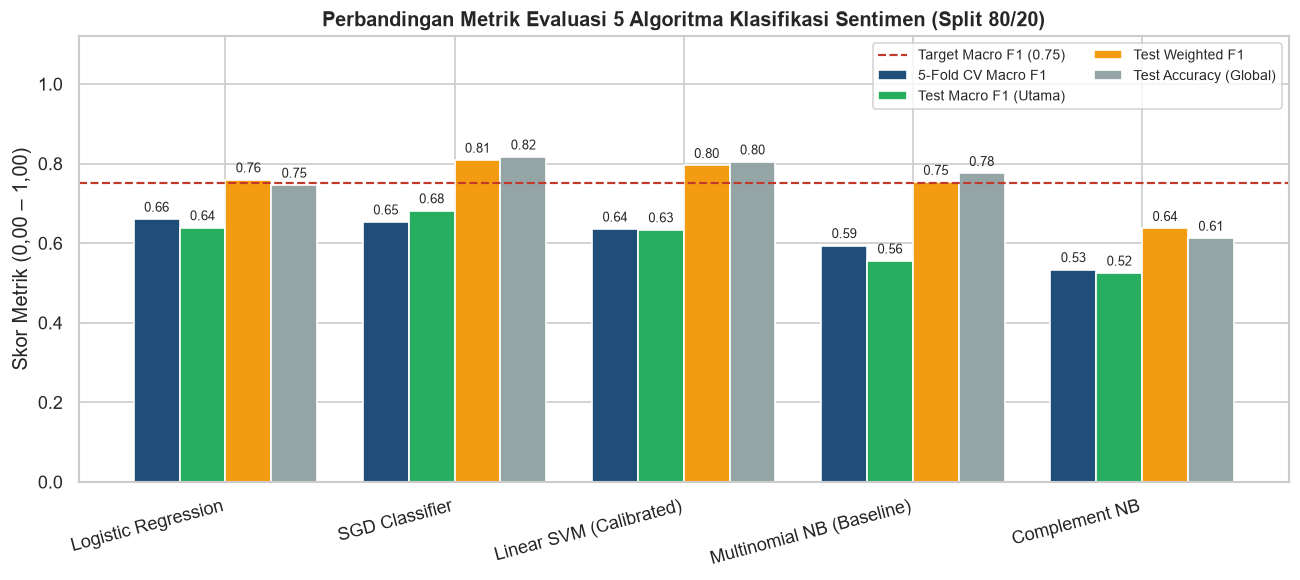

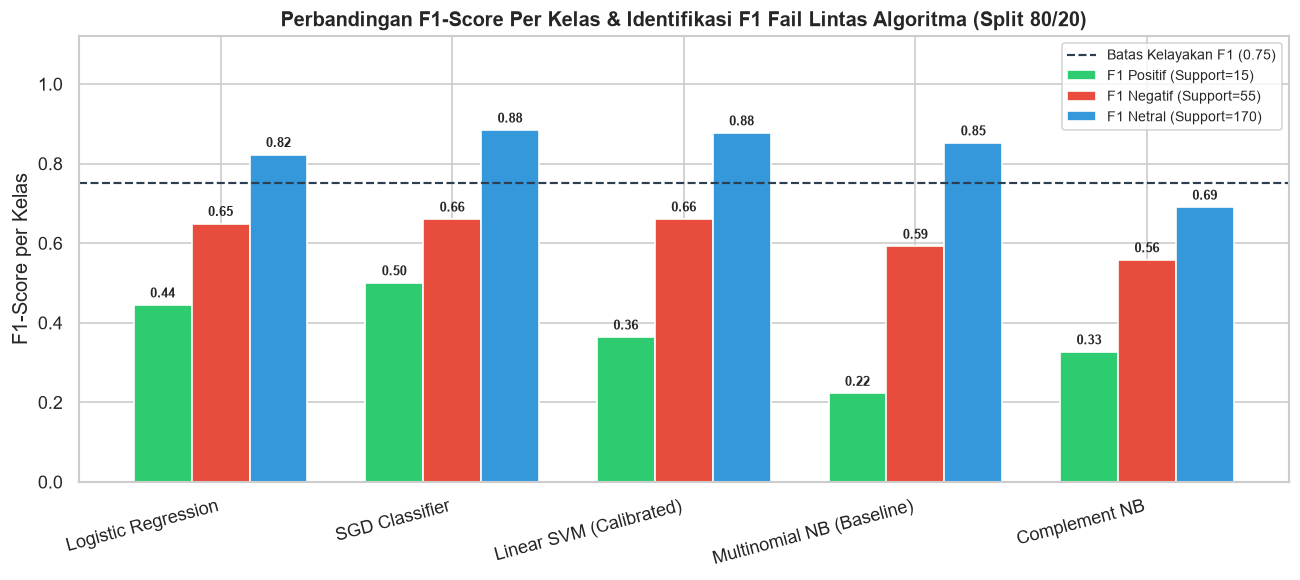

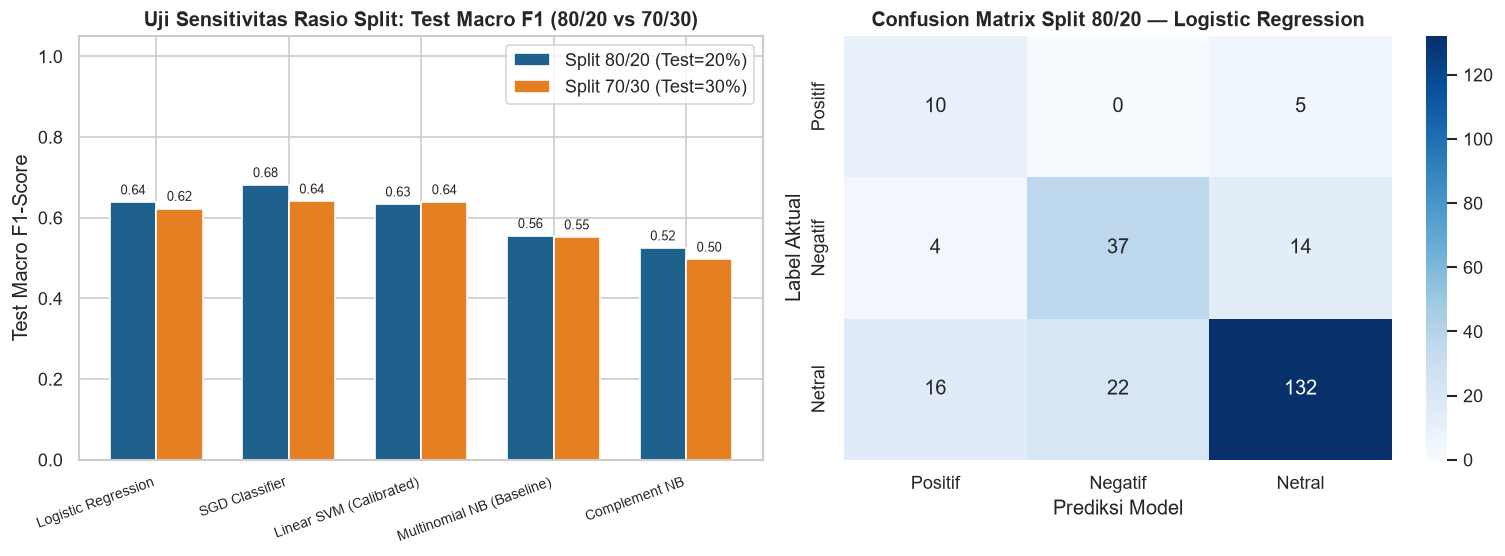


Artefak final berhasil disimpan ke: artifacts\sentiment_model.joblib dan artifacts\metrics.json


In [18]:
# === CELL 16 (REVISI): EKSPERIMEN LENGKAP JALUR B, IMBALANCE, 80/20 vs 70/30, F1 FAIL & CHART BATANG ===
import json
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.utils import resample
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titleweight"] = "bold"

FIGURES_DIR = Path("figures")
ARTIFACTS_DIR = Path("artifacts")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

if "df_labeled" not in globals() or "preprocess_indonesian_text" not in globals():
    raise RuntimeError("Jalankan Cell 15 terlebih dahulu agar 'df_labeled' dan fungsi preprocessing tersedia.")

LABELS_ORDER = ["Positif", "Negatif", "Netral"]
TARGET_MACRO_F1 = 0.75        # Target keberhasilan Bab 1.4
CONFIDENCE_THRESHOLD = 0.60   # Ambang batas operasional (Poin 1 dosen): < 0.60 -> perlu tinjauan manual
CV_SCHEME = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def highlight_winner(row):
    if "TERPILIH" in str(row.get("Status", "")):
        return ["background-color: #D4EFDF; font-weight: bold; color: #145A32"] * len(row)
    return [""] * len(row)

# ==============================================================================
# 0. SPLIT UTAMA 80/20 STRATIFIED (DATA LATIH UNTUK SELEKSI MODEL)
# ==============================================================================
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    df_labeled["Komentar"],
    df_labeled["Sentimen"],
    test_size=0.20,
    stratify=df_labeled["Sentimen"],
    random_state=42,
)

# ==============================================================================
# EKSPERIMEN 1: ABLASI NORMALISASI SINGKATAN, STOPWORD & N-GRAM TF-IDF (5-FOLD CV)
# ==============================================================================
ablation_configs = [
    ("Varian 1: Singkatan + Stopword (Negasi Utuh) + TF-IDF (1,2)", True, True, (1, 2)),
    ("Varian 2: Singkatan + Stopword (Negasi Utuh) + TF-IDF (1,1)", True, True, (1, 1)),
    ("Varian 3: Singkatan + Tanpa Stopword + TF-IDF (1,2)", True, False, (1, 2)),
    ("Varian 4: Tanpa Singkatan + Stopword + TF-IDF (1,2)", False, True, (1, 2)),
]

ablation_rows = []
for label_cfg, norm_slang, rm_sw, ngram in ablation_configs:
    X_tr_tmp = X_train_80.apply(
        lambda s: preprocess_indonesian_text(s, remove_stopwords=rm_sw, normalize_slang=norm_slang)
    )
    vec_tmp = TfidfVectorizer(ngram_range=ngram, min_df=2, max_features=8000, sublinear_tf=True)
    X_tr_vec_tmp = vec_tmp.fit_transform(X_tr_tmp)
    scores = cross_val_score(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
        X_tr_vec_tmp, y_train_80, cv=CV_SCHEME, scoring="f1_macro"
    )
    ablation_rows.append({
        "Konfigurasi_Fitur": label_cfg,
        "Norm_Singkatan": norm_slang,
        "Remove_Stopwords": rm_sw,
        "Ngram_Range": str(ngram),
        "CV_Macro_F1_Mean": scores.mean(),
        "CV_Macro_F1_Std": scores.std(),
    })

df_ablation = pd.DataFrame(ablation_rows).sort_values("CV_Macro_F1_Mean", ascending=False).reset_index(drop=True)
df_ablation.insert(0, "Status", ["[TERPILIH]" if i == 0 else "Pembanding" for i in range(len(df_ablation))])

print("=== EKSPERIMEN 1: ABLASI PREPROCESSING SINGKATAN & TF-IDF (5-FOLD CV SPLIT 80/20) ===")
display(
    df_ablation.style.apply(highlight_winner, axis=1).format(
        {"CV_Macro_F1_Mean": "{:.4f}", "CV_Macro_F1_Std": "{:.4f}"}
    )
)

best_norm_slang = bool(df_ablation.loc[0, "Norm_Singkatan"])
best_rm_sw = bool(df_ablation.loc[0, "Remove_Stopwords"])
best_ngram = eval(df_ablation.loc[0, "Ngram_Range"])

# ==============================================================================
# EKSPERIMEN 2: PENANGANAN IMBALANCED DATA DI DALAM 5-FOLD CV (ANTI-LEAKAGE)
# ==============================================================================
X_train_80_clean = X_train_80.apply(
    lambda s: preprocess_indonesian_text(s, remove_stopwords=best_rm_sw, normalize_slang=best_norm_slang)
)

def evaluate_imbalance_strategy(X_text_s, y_s, strategy="Data Asli (None)"):
    X_arr = X_text_s.reset_index(drop=True)
    y_arr = y_s.reset_index(drop=True)
    f1_macros, accs, rec_pos, rec_neg, rec_net = [], [], [], [], []

    for tr_idx, va_idx in CV_SCHEME.split(X_arr, y_arr):
        df_fold = pd.DataFrame({"text": X_arr.iloc[tr_idx], "label": y_arr.iloc[tr_idx]})
        X_va_fold, y_va_fold = X_arr.iloc[va_idx], y_arr.iloc[va_idx]

        # Resampling HANYA dilakukan pada fold latih agar fold validasi tidak bocor
        if strategy == "Random Oversampling":
            max_n = df_fold["label"].value_counts().max()
            df_fold = pd.concat(
                [resample(g, replace=True, n_samples=max_n, random_state=42) for _, g in df_fold.groupby("label")],
                ignore_index=True,
            )
        elif strategy == "Random Undersampling":
            min_n = df_fold["label"].value_counts().min()
            df_fold = pd.concat(
                [resample(g, replace=False, n_samples=min_n, random_state=42) for _, g in df_fold.groupby("label")],
                ignore_index=True,
            )

        vec = TfidfVectorizer(ngram_range=best_ngram, min_df=2, max_features=8000, sublinear_tf=True)
        X_tr_v = vec.fit_transform(df_fold["text"])
        X_va_v = vec.transform(X_va_fold)

        cw = "balanced" if strategy == "class_weight='balanced'" else None
        clf = LogisticRegression(max_iter=1000, class_weight=cw, random_state=42)
        clf.fit(X_tr_v, df_fold["label"])
        preds = clf.predict(X_va_v)

        _, rec_arr, _, _ = precision_recall_fscore_support(y_va_fold, preds, labels=LABELS_ORDER, zero_division=0)
        f1_macros.append(f1_score(y_va_fold, preds, average="macro"))
        accs.append(accuracy_score(y_va_fold, preds))
        rec_pos.append(rec_arr[0])
        rec_neg.append(rec_arr[1])
        rec_net.append(rec_arr[2])

    return {
        "Strategi_Penanganan_Imbalance": strategy,
        "CV_Macro_F1": np.mean(f1_macros),
        "CV_Accuracy": np.mean(accs),
        "CV_Recall_Positif": np.mean(rec_pos),
        "CV_Recall_Negatif": np.mean(rec_neg),
        "CV_Recall_Netral": np.mean(rec_net),
    }

imbalance_strategies = [
    "Data Asli (None)",
    "class_weight='balanced'",
    "Random Oversampling",
    "Random Undersampling",
]
df_imbalance = (
    pd.DataFrame([evaluate_imbalance_strategy(X_train_80_clean, y_train_80, s) for s in imbalance_strategies])
    .sort_values("CV_Macro_F1", ascending=False)
    .reset_index(drop=True)
)
df_imbalance.insert(0, "Status", ["[TERPILIH]" if i == 0 else "Pembanding" for i in range(len(df_imbalance))])

print("\n=== EKSPERIMEN 2: PERBANDINGAN STRATEGI PENANGANAN IMBALANCED DATA (5-FOLD CV) ===")
display(
    df_imbalance.style.apply(highlight_winner, axis=1).format({
        "CV_Macro_F1": "{:.4f}", "CV_Accuracy": "{:.4f}",
        "CV_Recall_Positif": "{:.4f}", "CV_Recall_Negatif": "{:.4f}", "CV_Recall_Netral": "{:.4f}"
    })
)

# ==============================================================================
# EKSPERIMEN 3: BENCHMARKING 5 ALGORITMA PADA SPLIT 80/20 VS 70/30
# ==============================================================================
def run_benchmark_for_split(df_data, test_size=0.20, random_state=42):
    split_tag = f"{int(round((1 - test_size) * 100))}/{int(round(test_size * 100))}"
    X_tr, X_te, y_tr, y_te = train_test_split(
        df_data["Komentar"], df_data["Sentimen"],
        test_size=test_size, stratify=df_data["Sentimen"], random_state=random_state
    )
    X_tr_c = X_tr.apply(lambda s: preprocess_indonesian_text(s, remove_stopwords=best_rm_sw, normalize_slang=best_norm_slang))
    X_te_c = X_te.apply(lambda s: preprocess_indonesian_text(s, remove_stopwords=best_rm_sw, normalize_slang=best_norm_slang))

    vec = TfidfVectorizer(ngram_range=best_ngram, min_df=2, max_features=8000, sublinear_tf=True)
    X_tr_v = vec.fit_transform(X_tr_c)
    X_te_v = vec.transform(X_te_c)

    candidate_models = {
        "Multinomial NB (Baseline)": (
            MultinomialNB(),
            {"alpha": [0.1, 0.5, 1.0]},
        ),
        "Complement NB": (
            ComplementNB(),
            {"alpha": [0.1, 0.5, 1.0]},
        ),
        "Logistic Regression": (
            LogisticRegression(max_iter=1000, random_state=42),
            {"C": [0.25, 0.5, 1.0, 2.0], "class_weight": [None, "balanced"]},
        ),
        "Linear SVM (Calibrated)": (
            CalibratedClassifierCV(estimator=LinearSVC(dual="auto", random_state=42), cv=3, ensemble=False),
            {"estimator__C": [0.25, 0.5, 1.0, 2.0], "estimator__class_weight": [None, "balanced"]},
        ),
        "SGD Classifier": (
            SGDClassifier(loss="log_loss", max_iter=1000, random_state=42),
            {"alpha": [1e-5, 1e-4, 1e-3], "penalty": ["l2", "elasticnet"], "class_weight": [None, "balanced"]},
        ),
    }

    rows = []
    fitted = {}
    for m_name, (est, grid) in candidate_models.items():
        gs = GridSearchCV(est, grid, scoring="f1_macro", cv=CV_SCHEME, n_jobs=-1, refit=True)
        gs.fit(X_tr_v, y_tr)
        fitted[m_name] = gs

        preds = gs.predict(X_te_v)
        p_arr, r_arr, f1_arr, sup_arr = precision_recall_fscore_support(
            y_te, preds, labels=LABELS_ORDER, zero_division=0
        )
        f1_map = dict(zip(LABELS_ORDER, f1_arr))
        fail_cls = min(f1_map, key=f1_map.get)
        best_idx = gs.best_index_

        rows.append({
            "Split": split_tag,
            "Model": m_name,
            "CV_Macro_F1": gs.best_score_,
            "CV_Std": gs.cv_results_["std_test_score"][best_idx],
            "Test_Accuracy": accuracy_score(y_te, preds),
            "Test_Macro_F1": f1_score(y_te, preds, average="macro"),
            "Test_Weighted_F1": f1_score(y_te, preds, average="weighted"),
            "Precision_Pos": p_arr[0], "Recall_Pos": r_arr[0], "F1_Positif": f1_arr[0], "Support_Pos": int(sup_arr[0]),
            "Precision_Neg": p_arr[1], "Recall_Neg": r_arr[1], "F1_Negatif": f1_arr[1], "Support_Neg": int(sup_arr[1]),
            "Precision_Net": p_arr[2], "Recall_Net": r_arr[2], "F1_Netral": f1_arr[2], "Support_Net": int(sup_arr[2]),
            "Support_Total": int(sup_arr.sum()),
            "Support (Pos/Neg/Net)": f"{sup_arr[0]}/{sup_arr[1]}/{sup_arr[2]}",
            "F1_Fail (Kelas Terendah)": f"{fail_cls} ({f1_map[fail_cls]:.4f})",
            "Best_Params": str(gs.best_params_),
        })

    # Urutkan berdasarkan CV_Macro_F1 (seleksi bebas kebocoran data uji)
    df_res = pd.DataFrame(rows).sort_values("CV_Macro_F1", ascending=False).reset_index(drop=True)
    df_res.insert(0, "Status", ["[TERPILIH - MODEL TERBAIK]" if i == 0 else "Pembanding" for i in range(len(df_res))])
    return df_res, fitted, vec, (X_tr, X_te, y_tr, y_te, X_tr_v, X_te_v)

df_bench_80, fitted_80, tfidf_80, split_pack_80 = run_benchmark_for_split(df_labeled, test_size=0.20, random_state=42)
df_bench_70, fitted_70, tfidf_70, split_pack_70 = run_benchmark_for_split(df_labeled, test_size=0.30, random_state=42)

cols_show = [
    "Status", "Split", "Model", "CV_Macro_F1", "Test_Macro_F1", "Test_Weighted_F1",
    "Test_Accuracy", "F1_Positif", "F1_Negatif", "F1_Netral", "Recall_Neg",
    "Support (Pos/Neg/Net)", "F1_Fail (Kelas Terendah)", "Best_Params"
]
fmt_dict = {
    "CV_Macro_F1": "{:.4f}", "Test_Macro_F1": "{:.4f}", "Test_Weighted_F1": "{:.4f}",
    "Test_Accuracy": "{:.4f}", "F1_Positif": "{:.4f}", "F1_Negatif": "{:.4f}",
    "F1_Netral": "{:.4f}", "Recall_Neg": "{:.4f}",
}

print("\n=== EKSPERIMEN 3A: HASIL LENGKAP 5 ALGORITMA — SPLIT UTAMA 80/20 (n_train=80%, n_test=20%) ===")
display(df_bench_80[cols_show].style.apply(highlight_winner, axis=1).format(fmt_dict))

print("\n=== EKSPERIMEN 3B: UJI SENSITIVITAS 5 ALGORITMA — SPLIT PEMBANDING 70/30 (n_train=70%, n_test=30%) ===")
display(df_bench_70[cols_show].style.apply(highlight_winner, axis=1).format(fmt_dict))

# Tabel Perbandingan Langsung 80/20 vs 70/30 per Algoritma
df_split_compare = df_bench_80[["Model", "CV_Macro_F1", "Test_Macro_F1", "Test_Accuracy", "F1_Positif", "F1_Negatif", "F1_Netral"]].merge(
    df_bench_70[["Model", "CV_Macro_F1", "Test_Macro_F1", "Test_Accuracy", "F1_Positif", "F1_Negatif", "F1_Netral"]],
    on="Model", suffixes=("_80_20", "_70_30")
)
df_split_compare["Selisih_MacroF1 (80/20 - 70/30)"] = (
    df_split_compare["Test_Macro_F1_80_20"] - df_split_compare["Test_Macro_F1_70_30"]
)
print("\n=== RINGKASAN PERBANDINGAN RASIO SPLIT 80/20 VS 70/30 ===")
display(df_split_compare.round(4))

# ==============================================================================
# EKSPERIMEN 4: BEDAH F1 FAIL, ERROR ANALYSIS, THRESHOLD & FEATURE IMPORTANCE (SPLIT UTAMA 80/20)
# ==============================================================================
winner_name = df_bench_80.loc[0, "Model"]
best_sentiment_clf = fitted_80[winner_name].best_estimator_
X_tr_80_raw, X_te_20_raw, y_tr_80_lbl, y_te_20_lbl, X_tr_80_vec, X_te_20_vec = split_pack_80

y_pred_20 = best_sentiment_clf.predict(X_te_20_vec)
y_proba_20 = best_sentiment_clf.predict_proba(X_te_20_vec)
max_conf_20 = y_proba_20.max(axis=1)

# 1. Laporan Klasifikasi Lengkap (Precision, Recall, F1, Support)
print(f"\n=== BEDAH EVALUASI DETAIL MODEL TERPILIH (SPLIT 80/20): {winner_name} ===")
print(classification_report(y_te_20_lbl, y_pred_20, labels=LABELS_ORDER, digits=4))

# 2. Identifikasi F1 Fail & Tabel Kasus Salah Prediksi (False Positive / False Negative)
p_w, r_w, f1_w, sup_w = precision_recall_fscore_support(y_te_20_lbl, y_pred_20, labels=LABELS_ORDER, zero_division=0)
df_per_class = pd.DataFrame({
    "Kelas": LABELS_ORDER,
    "Precision": p_w,
    "Recall": r_w,
    "F1_Score": f1_w,
    "Support": sup_w,
    "Gap_Ke_Target_0.75": f1_w - TARGET_MACRO_F1,
    "Status_Kelas": ["LULUS (>=0.75)" if v >= TARGET_MACRO_F1 else "F1 FAIL (<0.75)" for v in f1_w],
})
print("=== DETEKSI F1 FAIL PER KELAS (MODEL TERPILIH) ===")
display(df_per_class.round(4))

# Evaluasi Ambang Batas Operasional (Confidence Threshold)
df_err_20 = pd.DataFrame({
    "Komentar": X_te_20_raw.values,
    "Aktual": y_te_20_lbl.values,
    "Prediksi": y_pred_20,
    "Confidence": max_conf_20.round(4),
})
df_err_20["Status_Prediksi"] = np.where(df_err_20["Aktual"] == df_err_20["Prediksi"], "Benar", "Salah")
df_err_20["Keputusan_Operasional"] = np.where(
    df_err_20["Confidence"] >= CONFIDENCE_THRESHOLD,
    "Otomatis Dipublikasikan",
    f"Perlu Tinjauan Manual (Conf < {CONFIDENCE_THRESHOLD})"
)

low_conf_mask = df_err_20["Confidence"] < CONFIDENCE_THRESHOLD
high_conf_acc = (df_err_20.loc[~low_conf_mask, "Status_Prediksi"] == "Benar").mean() * 100
low_conf_err_rate = (df_err_20.loc[low_conf_mask, "Status_Prediksi"] == "Salah").mean() * 100 if low_conf_mask.any() else 0.0

print(f"\n=== SIMULASI AMBANG BATAS OPERASIONAL (CONFIDENCE THRESHOLD = {CONFIDENCE_THRESHOLD}) ===")
print(f"Prediksi Otomatis (Conf >= {CONFIDENCE_THRESHOLD}) : {(~low_conf_mask).sum()} komentar ({(~low_conf_mask).mean()*100:.1f}%) -> Akurasi: {high_conf_acc:.2f}%")
print(f"Antrean Review Manual (Conf < {CONFIDENCE_THRESHOLD}): {low_conf_mask.sum()} komentar ({low_conf_mask.mean()*100:.1f}%) -> Rasio Error di zona ini: {low_conf_err_rate:.2f}%")

# Tampilkan 10 sampel kesalahan (fokus pada kelas F1 terendah)
worst_cls = df_per_class.sort_values("F1_Score").iloc[0]["Kelas"]
df_fail_samples = df_err_20[
    (df_err_20["Status_Prediksi"] == "Salah")
    & ((df_err_20["Aktual"] == worst_cls) | (df_err_20["Prediksi"] == worst_cls))
].head(10)
if len(df_fail_samples) == 0:
    df_fail_samples = df_err_20[df_err_20["Status_Prediksi"] == "Salah"].head(10)

print(f"\n=== CONTOH KASUS F1 FAIL / KESALAHAN PREDIKSI (FOKUS KELAS: {worst_cls}) ===")
display(df_fail_samples)

# 3. Validitas Feature Importance (Poin 4 Dosen: tampilkan dengan uji kelayakan terhadap baseline)
baseline_f1 = float(df_bench_80.loc[df_bench_80["Model"] == "Multinomial NB (Baseline)", "Test_Macro_F1"].iloc[0])
winner_test_f1 = float(df_bench_80.loc[0, "Test_Macro_F1"])
winner_test_acc = float(df_bench_80.loc[0, "Test_Accuracy"])
winner_rec_neg = float(df_bench_80.loc[0, "Recall_Neg"])

def extract_top_tfidf_features(estimator, vectorizer, top_n=8):
    feat_names = np.array(vectorizer.get_feature_names_out())
    classes = list(estimator.classes_)
    coef = None
    if hasattr(estimator, "coef_"):
        coef = estimator.coef_
    elif hasattr(estimator, "feature_log_prob_"):
        coef = estimator.feature_log_prob_
    elif hasattr(estimator, "calibrated_classifiers_"):
        inner = estimator.calibrated_classifiers_[0].estimator
        if hasattr(inner, "coef_"):
            coef = inner.coef_
    if coef is None:
        return pd.DataFrame()
    out = []
    for idx, cls in enumerate(classes):
        top_idx = np.argsort(coef[idx])[::-1][:top_n]
        out.append({"Kelas_Sentimen": cls, "Top_Fitur_TFIDF_Terkuat": ", ".join(feat_names[top_idx])})
    return pd.DataFrame(out)

print(f"\n=== VALIDITAS FEATURE IMPORTANCE (Winner Test Macro F1 = {winner_test_f1:.4f} vs Baseline = {baseline_f1:.4f}) ===")
if winner_test_f1 > baseline_f1 and winner_test_f1 >= 0.50:
    print("Status: LAYAK DIINTERPRETASI (melampaui baseline), dengan catatan kelas F1 Fail tetap perlu kehati-hatian.")
    display(extract_top_tfidf_features(best_sentiment_clf, tfidf_80, top_n=8))
else:
    print("PERINGATAN METODOLOGIS (POIN 4 DOSEN): Performa model masih rendah; Feature Importance tidak layak dijadikan kesimpulan kausal.")

# ==============================================================================
# VISUALISASI 3 CHART BATANG PERBANDINGAN ALGORITMA & CONFUSION MATRIX (300 DPI)
# ==============================================================================

# --- CHART 1: Grouped Bar Chart Metrik Utama 5 Algoritma (Split 80/20) ---
fig, ax = plt.subplots(figsize=(11, 5))
models_list = df_bench_80["Model"].tolist()
x = np.arange(len(models_list))
w = 0.20

b1 = ax.bar(x - 1.5*w, df_bench_80["CV_Macro_F1"], width=w, label="5-Fold CV Macro F1", color="#1F4E79")
b2 = ax.bar(x - 0.5*w, df_bench_80["Test_Macro_F1"], width=w, label="Test Macro F1 (Utama)", color="#27AE60")
b3 = ax.bar(x + 0.5*w, df_bench_80["Test_Weighted_F1"], width=w, label="Test Weighted F1", color="#F39C12")
b4 = ax.bar(x + 1.5*w, df_bench_80["Test_Accuracy"], width=w, label="Test Accuracy (Global)", color="#95A5A6")

ax.axhline(TARGET_MACRO_F1, color="#C0392B", linestyle="--", linewidth=1.3, label=f"Target Macro F1 ({TARGET_MACRO_F1})")
ax.set_title("Perbandingan Metrik Evaluasi 5 Algoritma Klasifikasi Sentimen (Split 80/20)")
ax.set_xticks(x)
ax.set_xticklabels(models_list, rotation=15, ha="right")
ax.set_ylabel("Skor Metrik (0,00 – 1,00)")
ax.set_ylim(0, 1.12)
ax.legend(loc="upper right", ncol=2, fontsize=8.5)

for bars in [b1, b2, b3, b4]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.012, f"{h:.2f}", ha="center", va="bottom", fontsize=7.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "jalurB_1_perbandingan_algoritma_80_20.png", dpi=300)
plt.show()

# --- CHART 2: Grouped Bar Chart F1-Score Per Kelas (Menyorot Titik F1 Fail) ---
fig, ax = plt.subplots(figsize=(11, 5))
w3 = 0.25
c_pos = ax.bar(x - w3, df_bench_80["F1_Positif"], width=w3, label=f"F1 Positif (Support={df_bench_80['Support_Pos'].iloc[0]})", color="#2ECC71")
c_neg = ax.bar(x,      df_bench_80["F1_Negatif"], width=w3, label=f"F1 Negatif (Support={df_bench_80['Support_Neg'].iloc[0]})", color="#E74C3C")
c_net = ax.bar(x + w3, df_bench_80["F1_Netral"],  width=w3, label=f"F1 Netral (Support={df_bench_80['Support_Net'].iloc[0]})",  color="#3498DB")

ax.axhline(TARGET_MACRO_F1, color="#2C3E50", linestyle="--", linewidth=1.3, label=f"Batas Kelayakan F1 ({TARGET_MACRO_F1})")
ax.set_title("Perbandingan F1-Score Per Kelas & Identifikasi F1 Fail Lintas Algoritma (Split 80/20)")
ax.set_xticks(x)
ax.set_xticklabels(models_list, rotation=15, ha="right")
ax.set_ylabel("F1-Score per Kelas")
ax.set_ylim(0, 1.12)
ax.legend(loc="upper right", fontsize=8.5)

for bars in [c_pos, c_neg, c_net]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.012, f"{h:.2f}", ha="center", va="bottom", fontsize=8, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "jalurB_2_f1_per_kelas_dan_f1_fail.png", dpi=300)
plt.show()

# --- CHART 3: Perbandingan Split 80/20 vs 70/30 + Confusion Matrix Model Terpilih ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Kiri: Chart Batang Split 80/20 vs 70/30 (Test Macro F1)
w2 = 0.35
x_cmp = np.arange(len(df_split_compare))
s1 = axes[0].bar(x_cmp - w2/2, df_split_compare["Test_Macro_F1_80_20"], width=w2, label="Split 80/20 (Test=20%)", color="#1F618D")
s2 = axes[0].bar(x_cmp + w2/2, df_split_compare["Test_Macro_F1_70_30"], width=w2, label="Split 70/30 (Test=30%)", color="#E67E22")
axes[0].set_title("Uji Sensitivitas Rasio Split: Test Macro F1 (80/20 vs 70/30)")
axes[0].set_xticks(x_cmp)
axes[0].set_xticklabels(df_split_compare["Model"], rotation=20, ha="right", fontsize=8.5)
axes[0].set_ylabel("Test Macro F1-Score")
axes[0].set_ylim(0, 1.05)
axes[0].legend()
for bars in [s1, s2]:
    for bar in bars:
        h = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.012, f"{h:.2f}", ha="center", va="bottom", fontsize=8)

# Kanan: Confusion Matrix Model Terpilih (Split 80/20)
cm_20 = confusion_matrix(y_te_20_lbl, y_pred_20, labels=LABELS_ORDER)
sns.heatmap(cm_20, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS_ORDER, yticklabels=LABELS_ORDER, ax=axes[1])
axes[1].set_title(f"Confusion Matrix Split 80/20 — {winner_name}")
axes[1].set_xlabel("Prediksi Model")
axes[1].set_ylabel("Label Aktual")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "jalurB_3_split_80_20_vs_70_30_dan_cm.png", dpi=300)
plt.show()

# ==============================================================================
# EKSPOR ARTEFAK FINAL JALUR B & METRICS.JSON
# ==============================================================================
sentiment_artifact = {
    "model_name": winner_name,
    "vectorizer": tfidf_80,
    "classifier": best_sentiment_clf,
    "normalize_slang": best_norm_slang,
    "remove_stopwords": best_rm_sw,
    "ngram_range": best_ngram,
    "slang_map": SLANG_MAP_ID,
    "stopwords": STOPWORDS_ID,
    "negation_words": NEGATION_WORDS,
    "classes": list(best_sentiment_clf.classes_),
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "benchmark_80_20": df_bench_80.to_dict(orient="records"),
    "benchmark_70_30": df_bench_70.to_dict(orient="records"),
    "imbalance_experiment": df_imbalance.to_dict(orient="records"),
    "test_metrics": {
        "macro_f1": round(winner_test_f1, 4),
        "weighted_f1": round(float(df_bench_80.loc[0, "Test_Weighted_F1"]), 4),
        "accuracy": round(winner_test_acc, 4),
        "recall_negatif": round(winner_rec_neg, 4),
    },
}
joblib.dump(sentiment_artifact, ARTIFACTS_DIR / "sentiment_model.joblib")

metrics_summary = {
    "jalur_a_selected": "Isolation Forest (n_estimators=300, contamination=0.05) + K-Means (k=3) Profiler",
    "jalur_b_selected": winner_name,
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "jalur_b_cv_macro_f1_80_20": round(float(df_bench_80.loc[0, "CV_Macro_F1"]), 4),
    "jalur_b_test_macro_f1_80_20": round(winner_test_f1, 4),
    "jalur_b_test_accuracy_80_20": round(winner_test_acc, 4),
    "jalur_b_test_recall_negatif_80_20": round(winner_rec_neg, 4),
    "jalur_b_test_macro_f1_70_30": round(
        float(df_bench_70.loc[df_bench_70["Model"] == winner_name, "Test_Macro_F1"].iloc[0]), 4
    ),
}
with open(ARTIFACTS_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, indent=2)

print(f"\nArtefak final berhasil disimpan ke: {ARTIFACTS_DIR / 'sentiment_model.joblib'} dan {ARTIFACTS_DIR / 'metrics.json'}")

=== KONFIRMASI SILANG JALUR A x JALUR B (JUMLAH KOMENTAR) ===


Pred_Sentimen,Negatif,Netral,Positif,All
Status_Akun_JalurA,,,,
Aktif Normal (>1 Komentar),3530,9053,1248,13831
Data Tidak Cukup (1 Komentar),9382,21792,4410,35584
Terindikasi Bot/Anomali,755,1588,146,2489
All,13667,32433,5804,51904



=== PROPORSI SENTIMEN PER KATEGORI AKUN (%) ===


Pred_Sentimen,Negatif,Netral,Positif
Status_Akun_JalurA,,,
Aktif Normal (>1 Komentar),25.52,65.45,9.02
Data Tidak Cukup (1 Komentar),26.37,61.24,12.39
Terindikasi Bot/Anomali,30.33,63.80,5.87



=== DAMPAK PENYARINGAN AKUN TERINDIKASI BOT TERHADAP OPINI PUBLIK ===


,Sebelum_Penyaringan (%),Sesudah_Penyaringan (%),Pergeseran (Poin %)
Pred_Sentimen,,,
Positif,11.18,11.45,0.27
Negatif,26.33,26.13,-0.20
Netral,62.49,62.42,-0.07


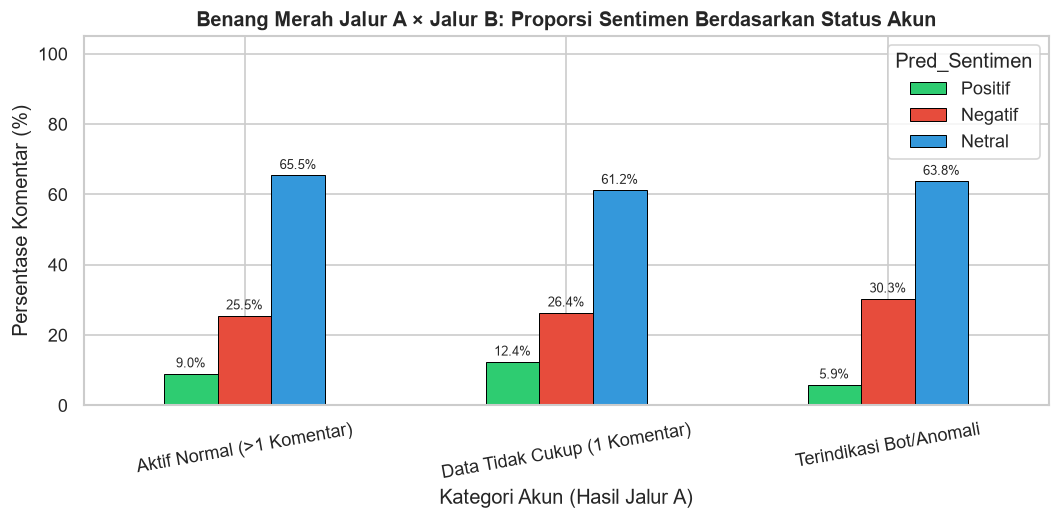

In [19]:
# === CELL 17: BENANG MERAH (INTEGRASI & KONFIRMASI SILANG JALUR A x JALUR B) ===
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ARTIFACTS_DIR = Path("artifacts")
FIGURES_DIR = Path("figures")

# Muat master dataset bersih + kedua artefak model
df_master = pd.read_csv(ARTIFACTS_DIR / "dataset_clean_master.csv")
acc_art = joblib.load(ARTIFACTS_DIR / "account_model.joblib")
sent_art = joblib.load(ARTIFACTS_DIR / "sentiment_model.joblib")

# 1. Prediksi sentimen seluruh 51.904 komentar bersih menggunakan model terbaik Jalur B
texts_clean_all = df_master["Komentar"].apply(
    lambda s: preprocess_indonesian_text(
        s, remove_stopwords=sent_art["remove_stopwords"], normalize_slang=sent_art["normalize_slang"]
    )
)
X_all_vec = sent_art["vectorizer"].transform(texts_clean_all)
df_master["Pred_Sentimen"] = sent_art["classifier"].predict(X_all_vec)
df_master["Pred_Confidence"] = sent_art["classifier"].predict_proba(X_all_vec).max(axis=1)

# 2. Petakan status akun dari Jalur A (Single / Normal / Terindikasi Anomali)
df_master["Tanggal_dt"] = pd.to_datetime(df_master["Tanggal"], errors="coerce")
acc_counts_map = df_master.groupby("Account_ID").size()

# Hitung fitur untuk akun >1 komentar dan prediksi via account_model.joblib
multi_ids = acc_counts_map[acc_counts_map > 1].index
df_multi = df_master[df_master["Account_ID"].isin(multi_ids)].sort_values(["Account_ID", "Tanggal_dt"])

rec = []
for aid, g in df_multi.groupby("Account_ID", sort=False):
    n_c = len(g)
    times = g["Tanggal_dt"].dropna().values
    span_h = float((times[-1] - times[0]) / np.timedelta64(1, "h")) if len(times) > 1 else 0.0
    mean_int_h = float(np.mean(np.diff(times) / np.timedelta64(1, "s"))) / 3600.0 if len(times) > 1 else 0.0
    tokens = " ".join(g["Komentar_Norm"].astype(str).tolist()).split()
    rec.append({
        "Account_ID": aid,
        "jumlah_komentar": n_c,
        "jumlah_source_unik": g["Source_ID"].nunique(),
        "rentang_aktivitas_jam": span_h,
        "rata_interval_jam": mean_int_h,
        "frekuensi_per_jam": n_c / max(span_h, 1.0),
        "rasio_duplikasi": 1.0 - (g["Komentar_Norm"].nunique() / n_c),
        "rata_panjang_karakter": float(g["Char_Len"].mean()),
        "keragaman_teks": (len(set(tokens)) / len(tokens)) if tokens else 0.0,
    })

df_feat_multi = pd.DataFrame(rec)
X_f = df_feat_multi[acc_art["feature_cols"]].values.astype(float).copy()
X_f[:, acc_art["skewed_idx"]] = np.log1p(np.maximum(X_f[:, acc_art["skewed_idx"]], 0.0))
X_f_scaled = acc_art["scaler"].transform(X_f)

iso_flags = acc_art["iso_model"].predict(X_f_scaled)  # -1 = Terindikasi Bot/Anomali
status_map = dict(zip(
    df_feat_multi["Account_ID"],
    np.where(iso_flags == -1, "Terindikasi Bot/Anomali", "Aktif Normal (>1 Komentar)")
))

df_master["Status_Akun_JalurA"] = df_master["Account_ID"].map(status_map).fillna("Data Tidak Cukup (1 Komentar)")

# 3. Tabel Silang Distribusi Sentimen: Sebelum vs Sesudah Penyaringan Akun Terindikasi Bot
ct_pct = pd.crosstab(df_master["Status_Akun_JalurA"], df_master["Pred_Sentimen"], normalize="index") * 100
ct_cnt = pd.crosstab(df_master["Status_Akun_JalurA"], df_master["Pred_Sentimen"], margins=True)

sebelum_filter = df_master["Pred_Sentimen"].value_counts(normalize=True) * 100
sesudah_filter = df_master[df_master["Status_Akun_JalurA"] != "Terindikasi Bot/Anomali"]["Pred_Sentimen"].value_counts(normalize=True) * 100
df_dampak = pd.DataFrame({
    "Sebelum_Penyaringan (%)": sebelum_filter,
    "Sesudah_Penyaringan (%)": sesudah_filter,
    "Pergeseran (Poin %)": sesudah_filter - sebelum_filter
}).reindex(["Positif", "Negatif", "Netral"]).round(2)

print("=== KONFIRMASI SILANG JALUR A x JALUR B (JUMLAH KOMENTAR) ===")
display(ct_cnt)
print("\n=== PROPORSI SENTIMEN PER KATEGORI AKUN (%) ===")
display(ct_pct.round(2))
print("\n=== DAMPAK PENYARINGAN AKUN TERINDIKASI BOT TERHADAP OPINI PUBLIK ===")
display(df_dampak)

# Visualisasi Dampak Penyaringan
ax = ct_pct[["Positif", "Negatif", "Netral"]].plot(
    kind="bar", figsize=(9, 4.5), color=["#2ECC71", "#E74C3C", "#3498DB"], edgecolor="black", linewidth=0.6
)
ax.set_title("Benang Merah Jalur A × Jalur B: Proporsi Sentimen Berdasarkan Status Akun")
ax.set_xlabel("Kategori Akun (Hasil Jalur A)")
ax.set_ylabel("Persentase Komentar (%)")
ax.set_ylim(0, 105)
plt.xticks(rotation=10)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "benang_merah_jalurA_x_jalurB.png", dpi=300)
plt.show()

In [22]:
# === CELL 16B (TAMBAHAN): SANITY CHECK KATA KASAR & AUTO-SYNC KE WEB VS CODE ===
import json
import shutil
from datetime import datetime
from pathlib import Path
import joblib
import numpy as np

ARTIFACTS_DIR = Path("artifacts")
VSCODE_ARTIFACTS = Path(r"C:\Users\vicen\Downloads\artifacts")
VSCODE_ARTIFACTS.mkdir(parents=True, exist_ok=True)

# 1. Muat artefak hasil Cell 16 yang baru selesai dijalankan
sent_art = joblib.load(ARTIFACTS_DIR / "sentiment_model.joblib")
vec_check = sent_art["vectorizer"]
clf_check = sent_art["classifier"]

# 2. Uji Kasus Nyata (Sanity Check kata kasar, slang, dukungan & netral)
sanity_cases = [
    "goblok tolol nih gibran",
    "goblok gibran",
    "tolol banget sih",
    "gibran bego dungu",
    "gblk bgt wapres ini",
    "bacot doang gak kerja",
    "semangat mas gibran",
    "siapa pengganti wapres nanti?",
]

print(f"=== SANITY CHECK MODEL TERBARU: {sent_art['model_name']} ===")
for txt in sanity_cases:
    cl = preprocess_indonesian_text(
        txt,
        remove_stopwords=sent_art["remove_stopwords"],
        normalize_slang=sent_art["normalize_slang"],
    )
    xv = vec_check.transform([cl])
    pr = clf_check.predict(xv)[0]
    pb = dict(zip(clf_check.classes_, np.round(clf_check.predict_proba(xv)[0] * 100, 1)))
    print(f"  '{txt:30s}' -> {pr:7s} | {pb}")

# 3. Auto-Sync menyalin model & metrics terbaru ke folder web VS Code (TA/artifacts/)
print("\n=== AUTO-SYNC KE FOLDER WEB VS CODE ===")

for fname in ["sentiment_model.joblib", "account_model.joblib", "metrics.json"]:
    src_f = ARTIFACTS_DIR / fname
    dst_f = VSCODE_ARTIFACTS / fname
    if src_f.exists():
        if src_f.resolve() != dst_f.resolve():
            shutil.copy2(src_f, dst_f)
        ts = datetime.fromtimestamp(dst_f.stat().st_mtime).strftime("%Y-%m-%d %H:%M:%S")
        print(f"  [OK] {fname:24s} -> {dst_f} (diperbarui: {ts})")


# 4. Verifikasi isi metrics.json yang sudah masuk ke TA/artifacts/
with open(VSCODE_ARTIFACTS / "metrics.json", "r", encoding="utf-8") as f:
    m_web = json.load(f)
print("\nVerifikasi Model Aktif di Web VS Code:")
print(f"  Model Terpilih : {m_web.get('jalur_b_selected')}")
print(f"  Test Macro F1  : {m_web.get('jalur_b_test_macro_f1_80_20')}")

=== SANITY CHECK MODEL TERBARU: Logistic Regression ===
  'goblok tolol nih gibran       ' -> Positif | {'Negatif': np.float64(20.0), 'Netral': np.float64(22.5), 'Positif': np.float64(57.5)}
  'goblok gibran                 ' -> Positif | {'Negatif': np.float64(20.0), 'Netral': np.float64(22.5), 'Positif': np.float64(57.5)}
  'tolol banget sih              ' -> Netral  | {'Negatif': np.float64(32.2), 'Netral': np.float64(50.7), 'Positif': np.float64(17.1)}
  'gibran bego dungu             ' -> Positif | {'Negatif': np.float64(20.0), 'Netral': np.float64(22.5), 'Positif': np.float64(57.5)}
  'gblk bgt wapres ini           ' -> Netral  | {'Negatif': np.float64(36.5), 'Netral': np.float64(45.1), 'Positif': np.float64(18.4)}
  'bacot doang gak kerja         ' -> Negatif | {'Negatif': np.float64(46.6), 'Netral': np.float64(37.2), 'Positif': np.float64(16.2)}
  'semangat mas gibran           ' -> Positif | {'Negatif': np.float64(9.2), 'Netral': np.float64(12.4), 'Positif': np.float64(78.4)}
